# 🏭 Lab 04b: Production-Grade RAG System

## Supplemental Lab after Module 04: Building and Evaluating a Real-World RAG Pipeline 🧪

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04b-production-rag-lab.ipynb)

> 🧭 **The decision.** Your team is about to ship a documentation assistant. The vendor tutorial says: chunk at 800 tokens with 400 overlap, use vector search, add a reranker. Each default sounds reasonable. **By the end of this lab you'll have measured each one on your own corpus, and at least one will turn out wrong for you.**

![Comic, four panels. The PM points at a sign reading 'Tutorial: 800 tok, 400 overlap, + reranker' and says to copy, paste, ship. The engineer asks which documents the settings were tuned on; the PM shrugs: 'Theirs. A cookbook, I think.' The engineer notes the team's docs are only 400 tokens long; the model cheers that each doc is then ONE 800-token chunk. Caption: a default is a hypothesis. The engineer: 'So we test every setting on OUR docs.' The PM: '…that's a lot of hypotheses.'](attachment:comic-defaults.png)

<sub>🖼️ *Every tutorial default was tuned on somebody else's corpus. This lab tests each one on yours.*</sub>

| | |
|---|---|
| ⏱️ **Time** | 60–70 min hands-on (the Weaviate and cross-encoder options add ~5 min each) |
| 🎚️ **Level** | Intermediate–advanced: you build and measure the pipeline yourself |
| 🔑 **Keys needed** | None. Optional `OPENAI_API_KEY` for real generation with `gpt-6-luna` |
| 🧰 **Tools** | `sentence-transformers` · `numpy`/`pandas`/`matplotlib` · optional `weaviate-client` v4 (embedded) · optional `openai` (Responses API) |
| 🔗 **Depends on Lab 04?** | No code dependency. The **📏 Metrics primer** below covers every metric |
| 🏁 **You'll leave with** | A chunking choice backed by evidence-level metrics, a measured hybrid/rerank decision, and a readiness `verdict()` |

---

## 🧭 Overview

You'll build a RAG system for a technical documentation assistant from scratch, then test every design decision instead of trusting defaults: **chunking** (scored with Chroma-style token-level metrics), **hybrid search** (BM25 + dense), **reranking**, and **generation** behind a `PROVIDER` switch.

### 🏗️ What You'll Build

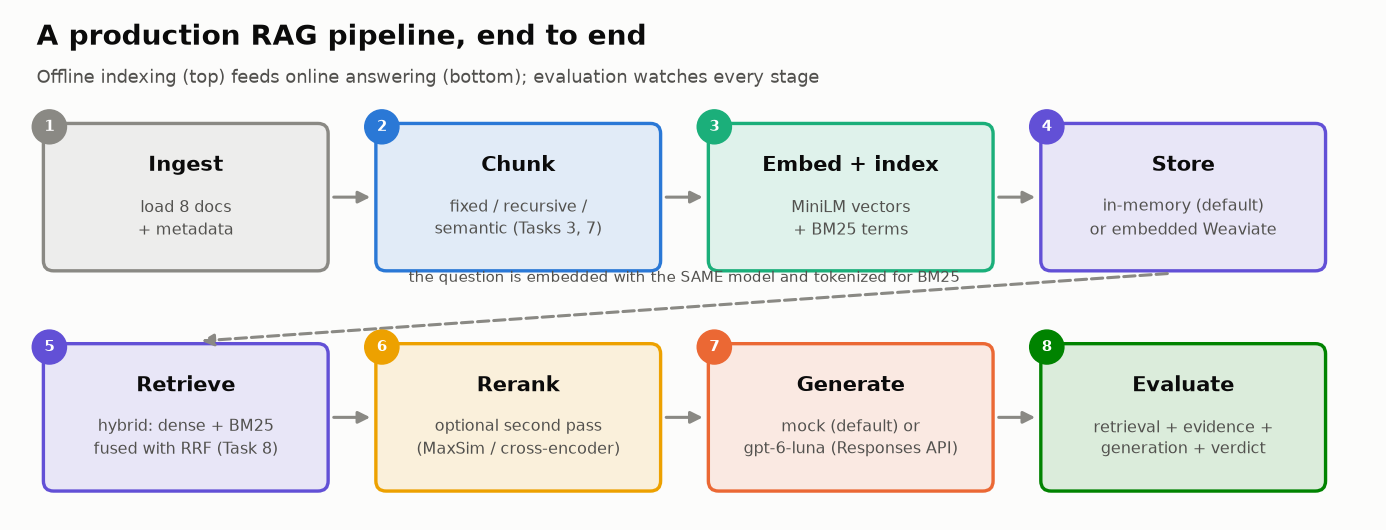

<sub>🖼️ *The eight stages you'll build: offline indexing on top, online answering below*</sub>

- ✅ A vector store behind a swappable adapter: in-memory (numpy + BM25) by default, **embedded Weaviate** optional
- ✅ Three chunkers (fixed-size, recursive, semantic) and a **chunk-size sweep** scored on evidence, not documents
- ✅ Five retrieval stacks (dense, BM25, hybrid, + context headers, + reranker) compared on retrieval-failure rate
- ✅ Generation with a mock (default) or `gpt-6-luna` via the OpenAI **Responses API**
- ✅ A production-readiness verdict

---

## 🎯 Learning Objectives

1. Build a modular RAG pipeline with a swappable vector-store adapter
2. Evaluate chunking with **token-level** metrics (evidence recall, IoU, tokens sent) and explain why document-level recall can't see the difference
3. Compare dense, BM25, hybrid and reranked retrieval with a **retrieval-failure rate** at the K you actually use
4. Generate answers behind a `PROVIDER` switch and read generation metrics next to retrieval metrics
5. Explain what RAGAS measures, how to call RAGAS 0.4, and why this lab doesn't depend on it
6. Make a production-readiness decision from evidence

---

## 📋 Prerequisites

- Module 01 (traces) recommended. Lab 04 helps but is **not required**
- Basic Python; embeddings and cosine similarity

---

## ⏱️ Estimated Time

**60–70 minutes.** Tasks 7 and 8 (chunk sweep; hybrid + rerank) are the heart of the lab. Short on time? Skim Task 10's RAGAS reference.

---

## ⚙️ Environment and Setup

- Google Colab or any Python 3.10+ kernel. CPU is fine.
- **Offline by default:** `PROVIDER = "mock"`, in-memory vector store, offline reranker. Run All works with no keys.
- Optional switches in Task 1: `PROVIDER = "openai"` (needs `OPENAI_API_KEY`), `USE_WEAVIATE = True`, `RERANKER = "cross-encoder"`.

---

## 🎬 Scenario

You're the ML engineer building a **technical documentation assistant** for *BrookPipe*, a (fictional) data-pipeline product. Management wants:
1. A working RAG pipeline with proper evaluation
2. A chunking strategy chosen with data, not vibes
3. A decision on whether hybrid search and reranking are worth their latency
4. A ship / no-ship recommendation

> 💼 **Why a docs bot in a fintech course?** The same defaults sit under every tax-help and bookkeeping assistant. There, a missed evidence span is a wrong filing deadline, and the 1.x migration guide plays last year's tax rules: a stale page that still *looks* relevant.
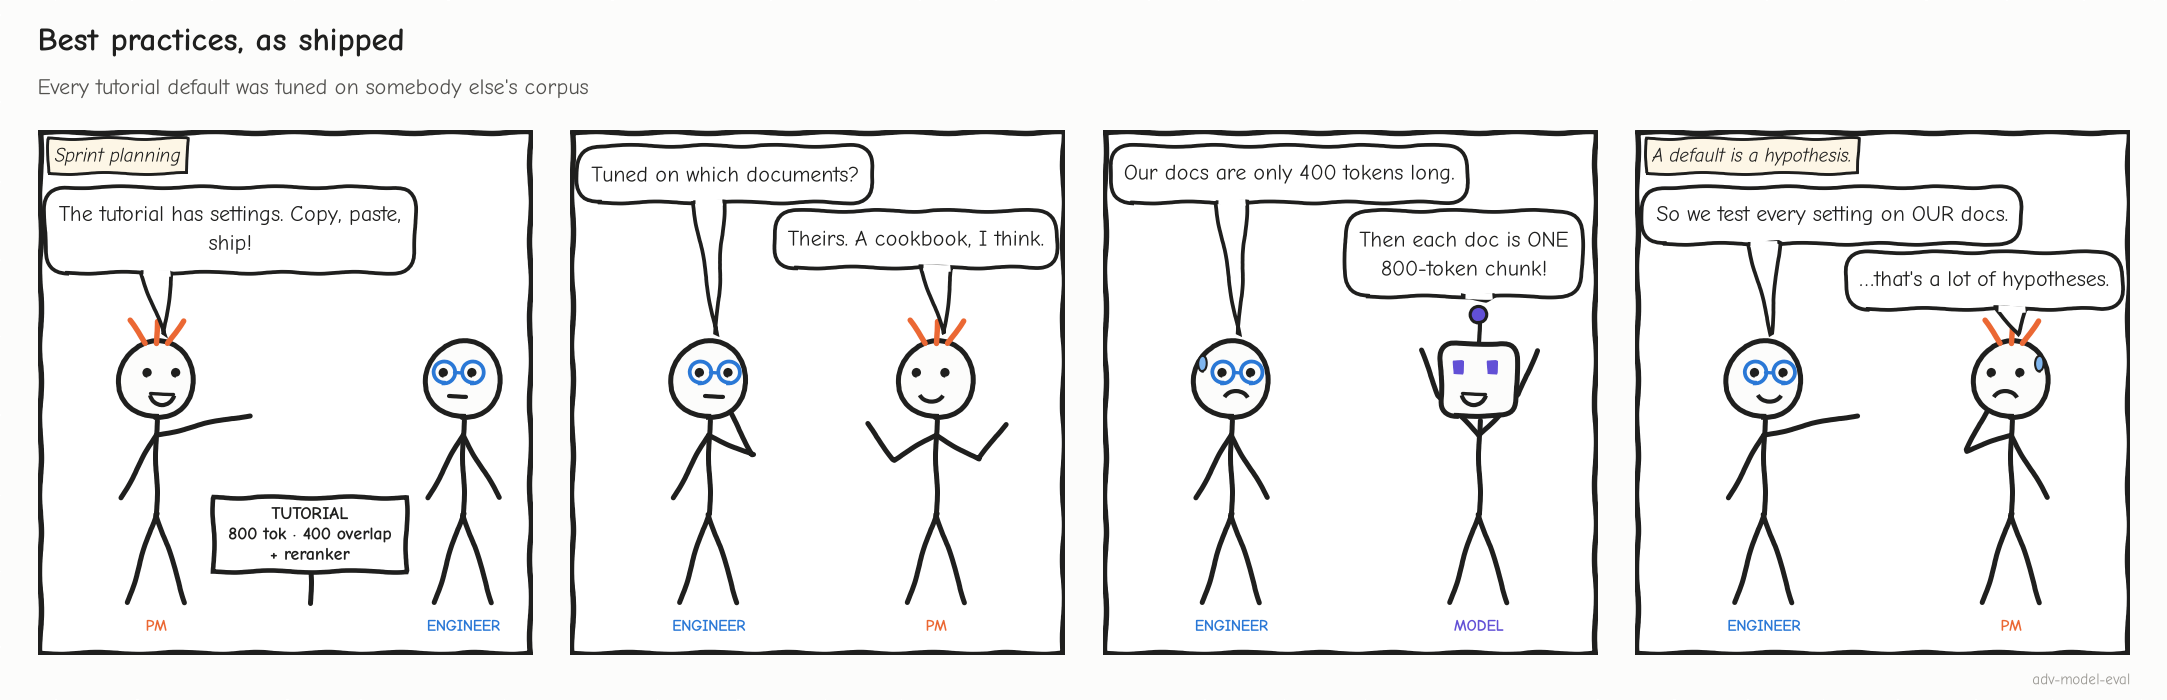

---

## 🗺️ Roadmap

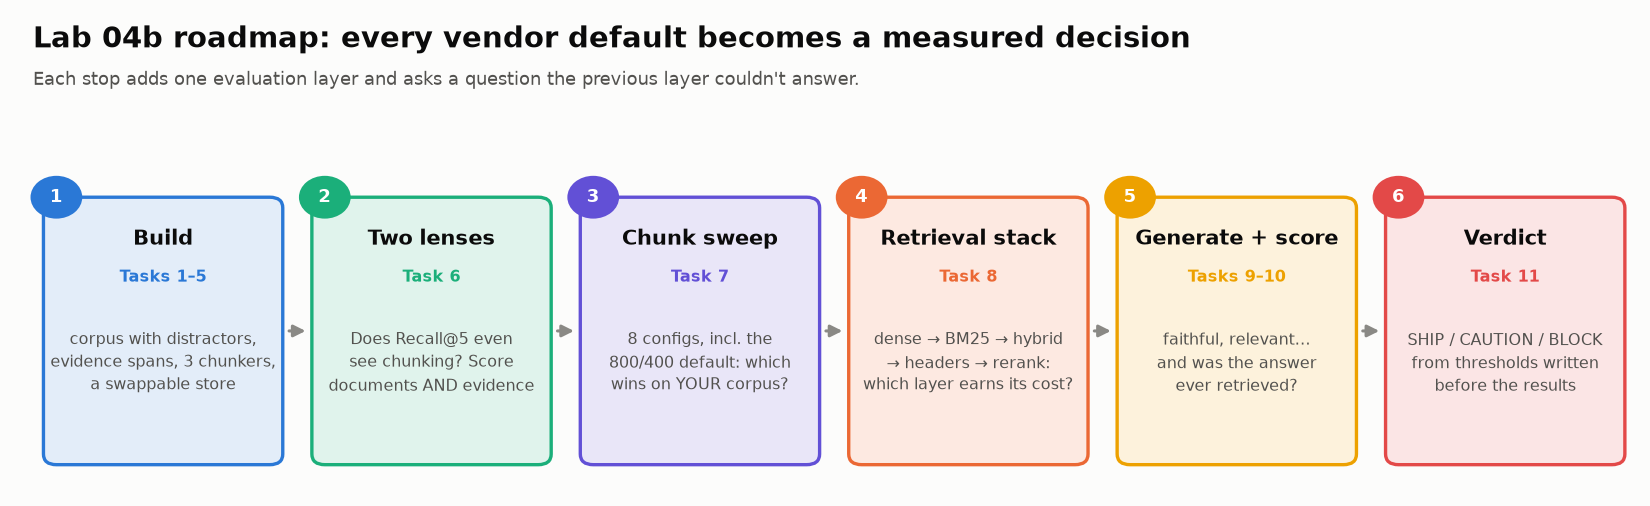

<sub>🖼️ *Six stops; each asks a question the previous layer couldn't answer*</sub>

<details>
<summary>📖 Jargon decoder: 34 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **RAG** (retrieval-augmented generation) | Look up relevant text first, then have the LLM answer from it | The whole lab |
| **Token** | The sub-word unit LLMs read and bill by; ≈ ¾ of an English word, ≈ 4 characters | Chunk sizes, cost (Tasks 3, 7) |
| **Chunk** | One indexed piece of a document: the unit you embed, retrieve and send | Task 3 |
| **Overlap** | Text repeated at the end of one chunk and the start of the next, so boundary sentences appear whole | Tasks 3, 7 |
| **Fixed / recursive / semantic chunking** | Cut every N tokens / cut at the coarsest natural break that fits / cut at section headings | Task 3 |
| **Embedding** | A list of numbers (384 here) a model assigns to a text; similar meanings point in similar directions | Task 4 |
| **Cosine similarity** | How closely two embeddings point the same way (1 = same, 0 = unrelated). Topical closeness, not "answers the question" | Tasks 4–5 |
| **Dense retrieval** | Rank chunks by cosine similarity to the question's embedding | Tasks 4, 8 |
| **BM25 (sparse retrieval)** | Classic keyword scoring: shared words count, rare words count more, long chunks count less | Tasks 4, 8 |
| **Hybrid search** | Run dense and BM25, then merge the two rankings | Tasks 4, 8 |
| **RRF** (Reciprocal Rank Fusion) | The merge rule: score = Σ 1 / (60 + rank). Uses ranks only, so score scales never matter | Task 4 diagram, Task 8 |
| **Top-K / K** | How many chunks you keep and pass to the generator | Every task |
| **Reranker** | A slower model that re-scores ~20 candidates and keeps the best K | Task 8 |
| **Bi-encoder vs cross-encoder** | Embed question and chunk separately and compare (fast) vs read them together in one model (slower, sharper) | Task 8 |
| **MaxSim** | This lab's offline reranker: score a chunk by its single best-matching sentence | Task 8 |
| **Context headers / Contextual Retrieval** | Index each chunk with "doc title > section" (free) / with an LLM-written summary (Anthropic, 2024) | Task 8 |
| **Distractor** | A doc that shares a question's vocabulary without being its best answer (here: the 1.x guide, the FAQ) | Tasks 2, 5, 8 |
| **Relevant document** | A document that contains the answer (`relevant_doc_ids`) | 📏 primer |
| **Evidence span** | The exact characters that answer a question (`evidence`) | 📏 primer, Task 6 |
| **Recall@K** | Share of relevant *documents* touched by the top-K chunks | Tasks 6–7 |
| **Precision@K** | Share of the top-K *chunks* that come from a relevant document | Task 6 |
| **nDCG@K** | Rank-weighted hit score: relevant chunks count more near the top (1.0 = ideal order) | Task 6 |
| **MRR** | Mean of 1 / rank of the first relevant chunk | Tasks 6, 8 |
| **Answer found / retrieval failure rate** | 1 if ≥ 50% of the evidence characters were retrieved / 1 − answer found | Tasks 6–11 |
| **IoU** (intersection over union) | Evidence ∩ sent ÷ evidence ∪ sent: punishes missing the answer *and* padding around it | Tasks 6–7 |
| **Vector database / embedded mode** | A store that answers nearest-neighbour queries / one running inside your Python process | Task 4 |
| **Adapter** | A thin interface (`recreate`, `insert`, `count`, `search`) so backends can be swapped | Task 4 |
| **Mock provider** | An offline stand-in generator; here it copies two context sentences, so it can't invent text | Tasks 9–11 |
| **Responses API** | OpenAI's current API for new projects (`client.responses.create`) | Task 9 |
| **Faithfulness / answer relevancy** | Is every answer claim in the context? / does the answer address the question? (word-overlap **proxies** here) | Task 10 |
| **Abstention / over-refusal** | Declining to answer / declining although the evidence *was* retrieved | Task 10 |
| **Parametric knowledge** | What an LLM memorized in training, as opposed to what you retrieved for it | Task 2 |
| **Context rot** | Quality loss as the prompt grows and fills with look-alike distractors | Task 9 |
| **Paired test (McNemar)** | Compare two systems on the *same* questions using only the ones they disagree on | 🏆 Challenge 2 |

</details>


---

## 📏 Metrics primer (read this if you skipped Lab 04)

Score retrieval and generation separately: a great retriever can't save a bad generator, and vice versa. Retrieval has two targets. A **relevant document** (`relevant_doc_ids`) contains the answer; document-level metrics ask whether any **chunk** (indexed piece) from it was retrieved. The **evidence span** (`evidence`) is the exact text that answers the question; evidence-level metrics ask whether *that text* was retrieved. A chunk can come from the right document and miss the span. (In Lab 04, "relevant" meant on-topic.)

| Level | Metric | Formula | 1.0 means |
|---|---|---|---|
| Document | **Recall@K** | relevant docs reached by the top-K chunks / all relevant docs | every relevant doc is represented |
| Document | **Precision@K** | top-K chunks from a relevant doc / K | every chunk sent is on target |
| Document | **nDCG@K** | DCG / ideal DCG, DCG = Σ rel / log₂(rank + 1), rel = 1 if the chunk is from a relevant doc | relevant chunks fill the top ranks |
| Document | **MRR** | mean of 1 / rank of the first relevant chunk | the first chunk is relevant, every time |
| Evidence | **Evidence recall** | evidence characters retrieved / evidence characters | the whole answer reached the LLM |
| Evidence | **Answer found** | 1 if evidence recall ≥ 0.5, else 0 (mean over questions) | the answer reached the LLM every time |
| Evidence | **Retrieval failure rate** | 1 − answer found | (lower is better) |
| Evidence | **IoU** | evidence ∩ retrieved / evidence ∪ retrieved | you sent the evidence and nothing else |
| Cost | **Tokens sent** | retrieved characters / 4 | (lower is cheaper) |
| Generation | **Faithfulness** | answer words found in the context / answer words | every answer word appears in the context |
| Generation | **Answer relevancy** | 0.5 + 0.5 × share of question words reused in the answer | every question word reappears in the answer |

*Example:* K = 5, the one relevant doc's chunk at rank 2 → Recall 1.00, Precision 0.20, nDCG 0.63, MRR 0.50. **Hit rate** (share of questions with ≥ 1 relevant doc in the top K) equals Recall@K here, because 13 of 14 questions have one relevant doc. Chroma (the vector-database company) calls the evidence metrics **token-level** in its 2024 study; this lab counts characters.

![Diagram: doc-004 with the 67-character evidence span for 'How do I configure retries?'. Four retrieved chunks from that same document all score Recall@K = 1.0: chunk A misses the span (answer found 0, IoU 0), chunk B holds it (IoU 0.096), the whole-document chunk C holds it with more padding (IoU 0.041), the semantic section D holds it tightly (IoU 0.183)](attachment:doc-vs-evidence.png)

<sub>🖼️ *Same document, four chunks, four Recall@K = 1.0 scores. Only the evidence metrics see that A misses the answer and C buries it.*</sub>

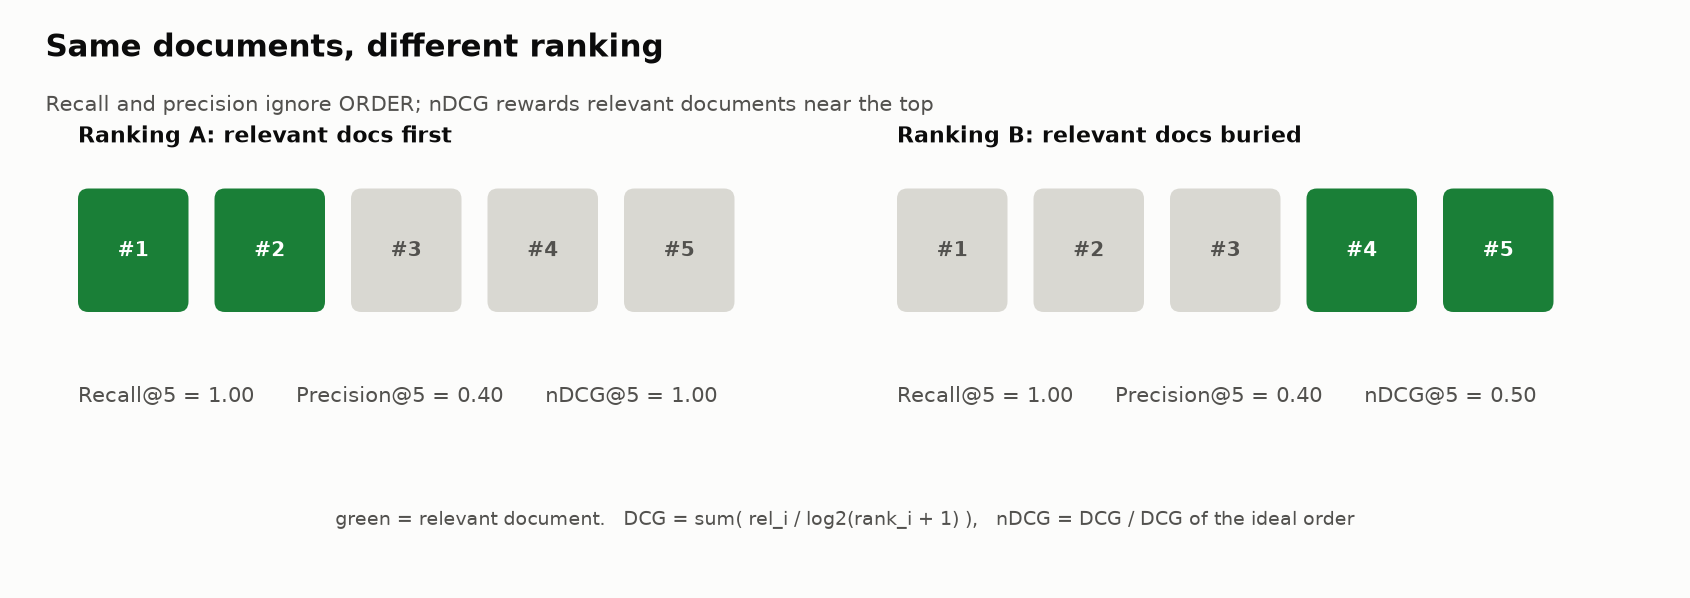

<sub>🖼️ *Recall and precision ignore order; nDCG and MRR reward putting relevant evidence first*</sub>

> 💡 **RAGAS vs. this lab.** RAGAS (an open-source RAG-evaluation library) scores faithfulness with an **LLM judge**, an LLM prompted to grade (extract the claims, verify each). This lab's generation metrics are word-overlap **proxies**, cheap stand-ins that move with the real metric without being it, so the lab runs free and offline. Task 10 shows the RAGAS 0.4 API as an optional reference.
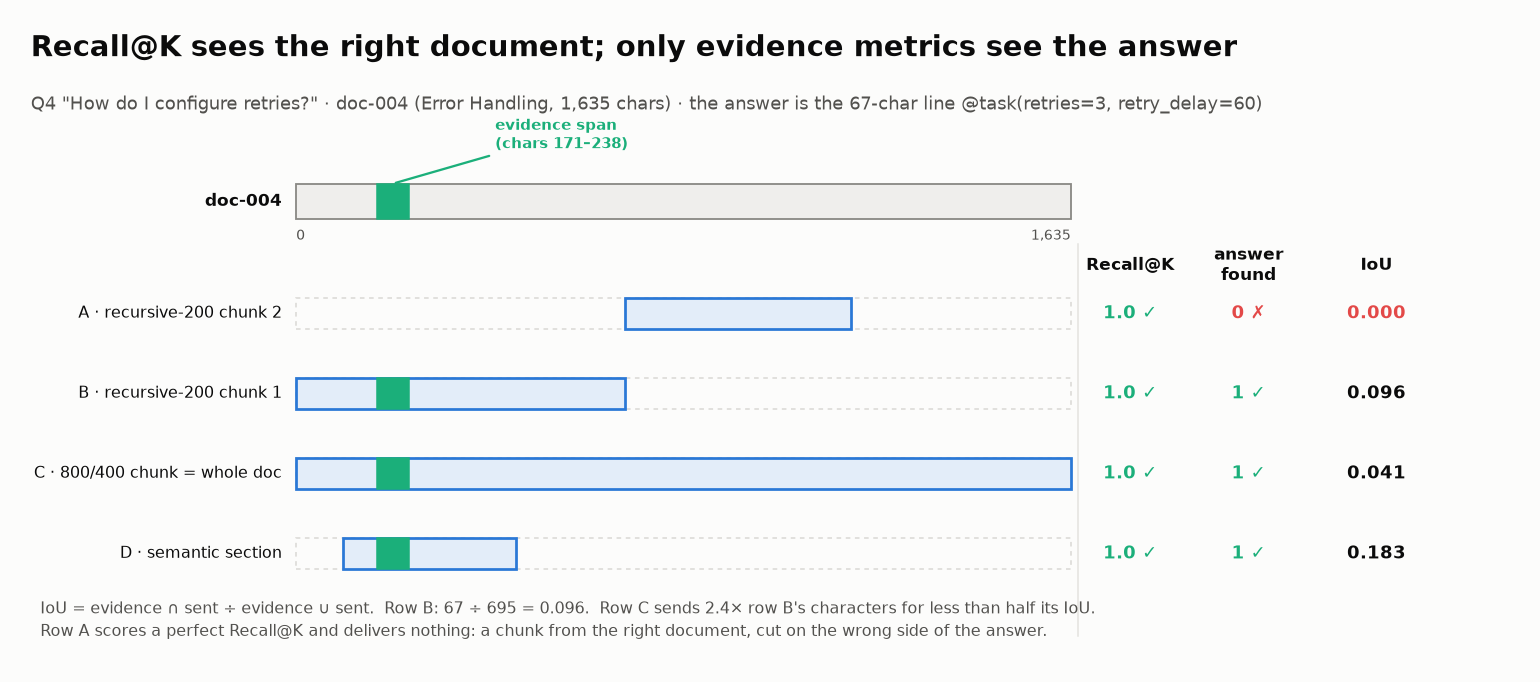

---

## 🔧 Task 1: Environment Setup

### Goal
Install packages, choose your options in **one config cell**, and load the course lab kit.

| Package | Purpose | Needed? |
|---------|---------|---------|
| `sentence-transformers` | Local embeddings (`all-MiniLM-L6-v2`) and the optional cross-encoder reranker | Yes |
| `pandas` / `numpy` / `matplotlib` | Tables, math, charts | Yes |
| `weaviate-client` (v4) | Embedded Weaviate vector DB | Only if `USE_WEAVIATE = True` |
| `openai` | Real generation with `gpt-6-luna` (Responses API) | Only if `PROVIDER = "openai"` |

### Steps
1. Run the install cell, then the imports cell.
2. Read the **config cell**, change a switch if you want an optional path, then run it.
3. Run the 🎨 Lab kit cell (you don't need to read it).

In [ ]:
%%capture
# - sentence-transformers : local embeddings + optional cross-encoder reranker (no API key needed)
# - weaviate-client v4    : OPTIONAL embedded vector DB (only used if USE_WEAVIATE = True)
# - openai                : OPTIONAL, only used if PROVIDER = "openai"
!pip install -q sentence-transformers pandas numpy matplotlib "weaviate-client>=4.16,<5" openai

In [ ]:
# ============================================================
# IMPORTS
# ============================================================
import os, re, json, math
from typing import List, Dict, Optional
from dataclasses import dataclass
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

pd.set_option("display.width", 160)
plt.rcParams["axes.axisbelow"] = True   # draw gridlines behind bars
print("✅ All imports successful!")

In [ ]:
# ============================================================
# LAB CONFIGURATION: the only cell you need to edit
# ============================================================
PROVIDER = "mock"            # "mock" (offline, default) | "openai" (needs OPENAI_API_KEY)
OPENAI_MODEL = "gpt-6-luna"  # OpenAI's named replacement for gpt-4o-mini (which shuts down 2027-01-14)
USE_WEAVIATE = False         # True = embedded Weaviate (downloads a ~150 MB server binary on first run)
RERANKER = "maxsim"          # "maxsim" (offline) | "cross-encoder" (downloads ~90 MB from Hugging Face)
K_CONTEXT = 3                # how many chunks the generator reads per question

if PROVIDER == "openai":
    OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY", "")
    try:                                     # Colab: add the key under 🔑 Secrets
        from google.colab import userdata
        OPENAI_API_KEY = userdata.get("OPENAI_API_KEY") or OPENAI_API_KEY
    except Exception:
        pass
    if OPENAI_API_KEY:
        os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
    else:
        print("⚠️ PROVIDER='openai' but no OPENAI_API_KEY found: falling back to the mock generator.")
        PROVIDER = "mock"

print(f"⚙️  PROVIDER={PROVIDER} · vector store={'Weaviate (embedded)' if USE_WEAVIATE else 'in-memory'} "
      f"· reranker={RERANKER} · K_CONTEXT={K_CONTEXT}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

### Checkpoint ✅
### Expected Output
```
✅ All imports successful!
⚙️  PROVIDER=mock · vector store=in-memory · reranker=maxsim · K_CONTEXT=3
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
```
If you set `PROVIDER = "openai"` without a key, you'll see a warning and the lab falls back to `mock`.

➡️ **Bridge:** an evaluation is only as good as its test set, so build that before any pipeline.

---

## 📂 Task 2: Create the Document Corpus and Evaluation Set

### Goal
Create the corpus (8 docs for the fictional *BrookPipe* product) and a 14-question evaluation set with ground truth, relevant document IDs, and the **exact evidence span** that answers each question.

### Why This Matters
- **Distractors are realistic.** A distractor shares vocabulary with a question without being its best answer. Docs 007 (a 1.x → 2.0 migration guide) and 008 (FAQ + error codes) mention configuration, retries, auth and alerts. Real corpora are full of near-duplicates and stale versions.
- **Evidence spans** let you measure whether the *answer text* reached the LLM, not just whether its *document* was touched. Task 6 shows why that matters.
- **Three question styles**: `standard` (written from the docs), `keyword` (exact identifiers like `BP-4031`), `paraphrase` (users' own words). Retrieval methods differ most across styles.

> ℹ️ The product name is fictional on purpose. An earlier version used "DataFlow": `pip install dataflow-sdk` is a real, unrelated PyPI package, and a real LLM would answer from what it memorized about Google Cloud Dataflow (its **parametric knowledge**) instead of from your docs.

> 🔮 **Predict:** which question style will plain vector search find hardest: standard, keyword, or paraphrase?

In [ ]:
# ============================================================
# SAMPLE DOCUMENT CORPUS: docs for "BrookPipe", a FICTIONAL data-pipeline product
# ============================================================
# ⚠️ BrookPipe doesn't exist. Commands inside these docs (`pip install brookpipe`,
#    `brookpipe dashboard`, ...) are part of the fake corpus: don't run them.
#
# Each document has: id, title, category, content (markdown).
# Docs 001–006 are the product guides. Doc 007 (a 1.x → 2.0 migration guide) and
# doc 008 (FAQ + error codes) are realistic *distractors*: they mention configuration,
# retries, auth and alerts too, but usually aren't the best answer.
#
# In production you'd load docs from S3/GCS, a CMS, a wiki export or a docs repo.

DOCUMENTS = [
    {
        "id": "doc-001",
        "title": "Getting Started with BrookPipe",
        "category": "quickstart",
        "content": """
# Getting Started with BrookPipe

BrookPipe is a modern data pipeline orchestration platform that helps you build, deploy, and monitor data workflows at scale.

## Installation

Install BrookPipe using pip:

```bash
pip install brookpipe
```

## Quick Start

Create your first pipeline in 3 steps:

1. **Define your pipeline** using Python decorators
2. **Configure sources and sinks** in YAML
3. **Deploy to BrookPipe Cloud** with one command

Example pipeline:

```python
from brookpipe import Pipeline, task

@task
def extract_data():
    return fetch_from_api()

@task
def transform_data(raw_data):
    return clean_and_validate(raw_data)

@task  
def load_data(clean_data):
    write_to_database(clean_data)

pipeline = Pipeline([extract_data, transform_data, load_data])
```

## Key Concepts

- **Pipeline**: A directed acyclic graph (DAG) of tasks
- **Task**: A single unit of work (Python function)
- **Trigger**: What starts a pipeline (schedule, event, API call)
- **Run**: A single execution of a pipeline

## Next Steps

- Read the Configuration Guide for advanced options
- Check out the Monitoring Guide to track your pipelines
- Join our Slack community for help
"""
    },
    {
        "id": "doc-002", 
        "title": "BrookPipe Configuration Guide",
        "category": "configuration",
        "content": """
# Configuration Guide

BrookPipe uses YAML configuration files to define pipeline settings, connections, and deployment options.

## Configuration File Location

BrookPipe looks for configuration in this order:
1. `./brookpipe.yaml` (current directory)
2. `~/.brookpipe/config.yaml` (user home)
3. `/etc/brookpipe/config.yaml` (system-wide)

## Basic Configuration

```yaml
# brookpipe.yaml
version: "2.0"

project:
  name: my-data-pipeline
  environment: production

connections:
  postgres:
    type: postgresql
    host: ${POSTGRES_HOST}
    port: 5432
    database: analytics
    credentials:
      secret: postgres-credentials

  s3:
    type: s3
    bucket: my-data-bucket
    region: us-west-2
```

## Environment Variables

Use `${VAR_NAME}` syntax to reference environment variables. This is the recommended way to handle secrets.

## Connection Types

BrookPipe supports these connection types:
- **postgresql**: PostgreSQL databases
- **mysql**: MySQL databases
- **s3**: Amazon S3 buckets
- **gcs**: Google Cloud Storage
- **kafka**: Apache Kafka topics
- **http**: REST APIs

## Pipeline-Specific Configuration

Each pipeline can override global settings:

```yaml
pipelines:
  daily-etl:
    schedule: "0 6 * * *"  # 6 AM daily
    timeout: 3600  # 1 hour
    retries: 3
    notifications:
      on_failure: slack-alerts
```

## Secrets Management

Never put secrets directly in config files. Use:
1. Environment variables
2. BrookPipe Secrets Manager
3. External secret managers (Vault, AWS Secrets Manager)
"""
    },
    {
        "id": "doc-003",
        "title": "BrookPipe Monitoring and Observability",
        "category": "monitoring",
        "content": """
# Monitoring and Observability

BrookPipe provides comprehensive monitoring capabilities to help you track pipeline health, debug issues, and optimize performance.

## Built-in Metrics

Every pipeline automatically tracks:
- **Run duration**: How long each run takes
- **Success/failure rate**: Percentage of successful runs
- **Task latency**: Time spent in each task
- **Data volume**: Rows processed, bytes transferred
- **Resource usage**: CPU, memory, network

## Dashboard

Access the monitoring dashboard at `https://app.brookpipe.example/monitoring` or run locally:

```bash
brookpipe dashboard
```

## Alerts

Configure alerts for pipeline issues:

```yaml
alerts:
  pipeline-failure:
    condition: run.status == "failed"
    channels: [slack, pagerduty]
    
  slow-pipeline:
    condition: run.duration > 2 * run.average_duration
    channels: [slack]
    
  data-quality:
    condition: metrics.null_rate > 0.05
    channels: [email]
```

## Logging

Logs are structured JSON by default. Configure log levels per task:

```python
@task(log_level="DEBUG")
def my_task():
    logger.info("Processing started", extra={"batch_id": 123})
```

## Integration with External Tools

BrookPipe integrates with:
- **Prometheus**: Metrics export
- **Grafana**: Dashboard templates
- **Datadog**: Full APM integration
- **PagerDuty**: Incident routing
- **Slack**: Notifications

## Debugging Failed Runs

When a run fails:
1. Check the run logs in the dashboard
2. Look at the failed task's stack trace
3. Review input data for that task
4. Use `brookpipe run --rerun-failed` to retry just failed tasks
"""
    },
    {
        "id": "doc-004",
        "title": "BrookPipe Error Handling",
        "category": "troubleshooting",
        "content": """
# Error Handling

BrookPipe provides robust error handling to ensure reliable pipeline execution.

## Retry Configuration

Configure retries at the task level:

```python
@task(retries=3, retry_delay=60)  # Retry 3 times, wait 60s between
def flaky_api_call():
    return requests.get(api_url).json()
```

Or at the pipeline level in YAML:

```yaml
pipelines:
  my-pipeline:
    retries: 3
    retry_delay: 60
    retry_backoff: exponential  # 60s, 120s, 240s
```

## Error Types

BrookPipe distinguishes between:
- **Transient errors**: Network timeouts, rate limits (auto-retry)
- **Data errors**: Invalid input data (requires fix)
- **Code errors**: Bugs in task code (requires code change)

## Dead Letter Queues

For streaming pipelines, configure DLQ to capture failed messages:

```yaml
pipelines:
  streaming-etl:
    dead_letter_queue:
      type: kafka
      topic: failed-messages
      retention: 7d
```

## Circuit Breakers

Prevent cascading failures with circuit breakers:

```python
@task(circuit_breaker={"failures": 5, "timeout": 300})
def external_api_task():
    # If this fails 5 times in 5 minutes, circuit opens
    return call_external_api()
```

## Handling Partial Failures

For batch processing, handle partial failures:

```python
@task(on_partial_failure="continue")  # Don't fail entire batch
def process_batch(records):
    results = []
    for record in records:
        try:
            results.append(process(record))
        except Exception as e:
            logger.error(f"Failed to process {record.id}", exc_info=e)
            results.append(ErrorRecord(record.id, str(e)))
    return results
```
"""
    },
    {
        "id": "doc-005",
        "title": "BrookPipe Security Best Practices",
        "category": "security",
        "content": """
# Security Best Practices

Follow these guidelines to secure your BrookPipe deployments.

## Authentication

BrookPipe supports multiple authentication methods:
- **API Keys**: For programmatic access
- **OAuth 2.0**: For user authentication
- **SAML**: For enterprise SSO

Never hardcode credentials. Use:

```python
# Bad - hardcoded credentials
conn = connect(password="secret123")

# Good - environment variable
conn = connect(password=os.environ["DB_PASSWORD"])

# Better - secrets manager
conn = connect(password=secrets.get("db-password"))
```

## Network Security

- Use VPC peering for database connections
- Enable TLS for all external connections
- Use private endpoints where available

## Data Encryption

BrookPipe encrypts data:
- **At rest**: AES-256 encryption
- **In transit**: TLS 1.3
- **In memory**: Secure memory handling

For sensitive data, enable column-level encryption:

```yaml
pipelines:
  pii-pipeline:
    encryption:
      columns: [ssn, credit_card, email]
      algorithm: AES-256-GCM
      key_id: pii-encryption-key
```

## Access Control

Use role-based access control (RBAC):

```yaml
roles:
  developer:
    - pipelines:read
    - pipelines:write
    - runs:read
    
  operator:
    - pipelines:read
    - runs:read
    - runs:trigger
    
  admin:
    - "*:*"
```

## Audit Logging

All actions are logged for compliance:
- Who did what
- When it happened  
- What data was accessed
- What changed
"""
    },
    {
        "id": "doc-006",
        "title": "BrookPipe Performance Optimization",
        "category": "performance",
        "content": """
# Performance Optimization

Optimize your BrookPipe pipelines for speed and efficiency.

## Parallelization

Run independent tasks in parallel:

```python
# These run in parallel automatically
@task
def extract_users():
    return fetch_users()

@task
def extract_orders():
    return fetch_orders()

@task
def join_data(users, orders):  # Waits for both
    return merge(users, orders)
```

## Batch Processing

Process data in batches to reduce overhead:

```python
@task(batch_size=1000)
def process_records(records):
    # Process 1000 records at a time
    return bulk_insert(records)
```

## Caching

Cache expensive computations:

```python
@task(cache_key="{date}", cache_ttl=3600)
def fetch_daily_data(date):
    # Cached for 1 hour per date
    return expensive_api_call(date)
```

## Resource Allocation

Allocate resources based on task needs:

```yaml
tasks:
  heavy-computation:
    resources:
      cpu: 4
      memory: 16GB
      gpu: 1
      
  light-task:
    resources:
      cpu: 0.5
      memory: 512MB
```

## Common Bottlenecks

1. **Database connections**: Use connection pooling
2. **API rate limits**: Implement backoff strategies
3. **Memory pressure**: Stream large datasets
4. **Network latency**: Co-locate with data sources
"""
    },
    {
        "id": "doc-007",
        "title": "Migrating from BrookPipe 1.x to 2.0",
        "category": "migration",
        "content": """
# Migrating from BrookPipe 1.x to 2.0

BrookPipe 2.0 changes several defaults. Read this guide before upgrading production pipelines.

## Configuration changes

In 1.x, configuration lived in a single `~/.brookpipe.yml` file. In 2.0 the search order changed; see the Configuration Guide. The `version` key must now be `"2.0"`.

## Retry syntax

The 1.x decorator `@task(max_retries=5)` is deprecated. Use `retries` and `retry_delay` instead. Pipeline-level retries in YAML are unchanged.

## Authentication

1.x supported API keys only. 2.0 adds OAuth 2.0 and SAML single sign-on. Existing API keys keep working.

## Monitoring and alerts

The 1.x `brookpipe status` command is replaced by the monitoring dashboard. Alert rules written for 1.x must be rewritten with the new `condition:` syntax.

## Removed features

- The `--legacy-scheduler` flag
- Python 3.8 support
- The built-in FTP connection type
"""
    },
    {
        "id": "doc-008",
        "title": "BrookPipe FAQ and Error Codes",
        "category": "faq",
        "content": """
# FAQ and Error Codes

## Does BrookPipe run on Windows?

Yes, through WSL 2. Native Windows support is planned.

## Why is my pipeline slower than expected?

The most common causes are missing connection pooling and unbatched writes. See the Performance Optimization guide.

## Can two pipelines share a task?

Yes. Import the task function into both pipeline definitions.

## Error codes

- **BP-1001**: configuration file not found. Check the search order in the Configuration Guide.
- **BP-2210**: connection refused by a source or sink. Check credentials and network rules.
- **BP-4031**: a task exceeded its `timeout`. Increase the timeout or split the task.
- **BP-5002**: the circuit breaker is open for this task. Wait for the breaker timeout or fix the upstream service.
"""
    }
]

print(f"✅ Created {len(DOCUMENTS)} documents for the RAG corpus")
print(f"   Categories: {set(d['category'] for d in DOCUMENTS)}")
print(f"   Total content: {sum(len(d['content']) for d in DOCUMENTS):,} characters")

In [ ]:
# ============================================================
# EVALUATION DATASET WITH GROUND TRUTH
# ============================================================
# For each question we store:
#   - ground_truth_answer : what a correct answer says
#   - relevant_doc_ids    : which documents contain the answer (for document-level metrics)
#   - evidence            : the EXACT text span(s) that answer it (for token-level metrics, Task 6)
#   - style               : "keyword" (exact identifiers), "paraphrase" (no doc vocabulary) or "standard"
#
# In production these come from user query logs, support tickets and SME annotation.

EVALUATION_DATASET = [
    {"question": "How do I install BrookPipe?",
     "ground_truth_answer": "Install BrookPipe using pip: pip install brookpipe",
     "relevant_doc_ids": ["doc-001"], "category": "installation", "style": "standard",
     "evidence": ["Install BrookPipe using pip:\n\n```bash\npip install brookpipe\n```"]},
    {"question": "Where does BrookPipe look for configuration files?",
     "ground_truth_answer": "In this order: ./brookpipe.yaml, ~/.brookpipe/config.yaml, /etc/brookpipe/config.yaml",
     "relevant_doc_ids": ["doc-002"], "category": "configuration", "style": "standard",
     "evidence": ["BrookPipe looks for configuration in this order:\n1. `./brookpipe.yaml` (current directory)\n2. `~/.brookpipe/config.yaml` (user home)\n3. `/etc/brookpipe/config.yaml` (system-wide)"]},
    {"question": "How can I monitor my pipeline's performance?",
     "ground_truth_answer": "BrookPipe tracks run duration, success/failure rate, task latency, data volume and resource usage; see the monitoring dashboard.",
     "relevant_doc_ids": ["doc-003"], "category": "monitoring", "style": "standard",
     "evidence": ["Every pipeline automatically tracks:\n- **Run duration**: How long each run takes\n- **Success/failure rate**: Percentage of successful runs\n- **Task latency**: Time spent in each task\n- **Data volume**: Rows processed, bytes transferred\n- **Resource usage**: CPU, memory, network"]},
    {"question": "How do I configure retries for failed tasks?",
     "ground_truth_answer": "At task level with @task(retries=3, retry_delay=60), or at pipeline level in YAML.",
     "relevant_doc_ids": ["doc-004"], "category": "troubleshooting", "style": "standard",
     "evidence": ["@task(retries=3, retry_delay=60)  # Retry 3 times, wait 60s between"]},
    {"question": "What authentication methods does BrookPipe support?",
     "ground_truth_answer": "API keys, OAuth 2.0 and SAML for enterprise SSO.",
     "relevant_doc_ids": ["doc-005"], "category": "security", "style": "standard",
     "evidence": ["- **API Keys**: For programmatic access\n- **OAuth 2.0**: For user authentication\n- **SAML**: For enterprise SSO"]},
    {"question": "How can I run tasks in parallel?",
     "ground_truth_answer": "Independent tasks run in parallel automatically.",
     "relevant_doc_ids": ["doc-006"], "category": "performance", "style": "standard",
     "evidence": ["Run independent tasks in parallel:"]},
    {"question": "How do I handle sensitive data like passwords?",
     "ground_truth_answer": "Never hardcode credentials; use environment variables or a secrets manager. Data is encrypted at rest with AES-256.",
     "relevant_doc_ids": ["doc-002", "doc-005"], "category": "security", "style": "standard",
     "evidence": ["Never put secrets directly in config files.", "Never hardcode credentials."]},
    {"question": "What is a Pipeline in BrookPipe?",
     "ground_truth_answer": "A Pipeline is a directed acyclic graph (DAG) of tasks.",
     "relevant_doc_ids": ["doc-001"], "category": "concepts", "style": "standard",
     "evidence": ["- **Pipeline**: A directed acyclic graph (DAG) of tasks"]},
    {"question": "How do I set up alerts for pipeline failures?",
     "ground_truth_answer": "Configure alerts in YAML with a condition such as run.status == \"failed\" and channels such as slack and pagerduty.",
     "relevant_doc_ids": ["doc-003"], "category": "monitoring", "style": "standard",
     "evidence": ["  pipeline-failure:\n    condition: run.status == \"failed\"\n    channels: [slack, pagerduty]"]},
    {"question": "What databases can BrookPipe connect to?",
     "ground_truth_answer": "PostgreSQL and MySQL (plus S3, GCS, Kafka and HTTP connections).",
     "relevant_doc_ids": ["doc-002"], "category": "configuration", "style": "standard",
     "evidence": ["- **postgresql**: PostgreSQL databases\n- **mysql**: MySQL databases"]},
    # --- exact identifiers: the kind of query keyword search is good at ---
    {"question": "What does error BP-4031 mean?",
     "ground_truth_answer": "A task exceeded its timeout; increase the timeout or split the task.",
     "relevant_doc_ids": ["doc-008"], "category": "troubleshooting", "style": "keyword",
     "evidence": ["**BP-4031**: a task exceeded its `timeout`. Increase the timeout or split the task."]},
    {"question": "What does --rerun-failed do?",
     "ground_truth_answer": "`brookpipe run --rerun-failed` retries just the failed tasks of a run.",
     "relevant_doc_ids": ["doc-003"], "category": "troubleshooting", "style": "keyword",
     "evidence": ["Use `brookpipe run --rerun-failed` to retry just failed tasks"]},
    # --- paraphrases: users don't use the docs' vocabulary ---
    {"question": "How do I stop one flaky third-party service from taking down everything downstream?",
     "ground_truth_answer": "Wrap the call in a circuit breaker, e.g. @task(circuit_breaker={\"failures\": 5, \"timeout\": 300}).",
     "relevant_doc_ids": ["doc-004"], "category": "troubleshooting", "style": "paraphrase",
     "evidence": ["Prevent cascading failures with circuit breakers:"]},
    {"question": "How are social security numbers protected in my tables?",
     "ground_truth_answer": "Enable column-level encryption (AES-256-GCM) for sensitive columns such as ssn.",
     "relevant_doc_ids": ["doc-005"], "category": "security", "style": "paraphrase",
     "evidence": ["For sensitive data, enable column-level encryption:"]},
]

# Locate every evidence span inside its document (character offsets). A span we can't find is a
# labeling bug, so fail loudly: evaluation data deserves the same tests as code.
DOC_TEXT = {d["id"]: d["content"].strip() for d in DOCUMENTS}
for item in EVALUATION_DATASET:
    spans = []
    for ev in item["evidence"]:
        hits = [(doc_id, text.find(ev)) for doc_id, text in DOC_TEXT.items()
                if doc_id in item["relevant_doc_ids"] and ev in text]
        assert hits, f"evidence not found for: {item['question']!r}"
        doc_id, start = hits[0]
        spans.append((doc_id, start, start + len(ev)))
    item["evidence_spans"] = spans

print(f"✅ Created {len(EVALUATION_DATASET)} evaluation questions with ground truth and evidence spans")
print(f"   Styles: {dict(Counter(q['style'] for q in EVALUATION_DATASET))}")

### Checkpoint ✅
### Expected Output
```
✅ Created 8 documents for the RAG corpus
   Categories: {...8 categories...}
   Total content: 10,308 characters
✅ Created 14 evaluation questions with ground truth and evidence spans
   Styles: {'standard': 10, 'keyword': 2, 'paraphrase': 2}
```
If you see `AssertionError: evidence not found`, an evidence string no longer matches its document exactly (did you edit a doc?).

> 💡 **Production insight:** an eval set is code. Assert that every label still points at real text, and grow the set from production queries.

➡️ **Bridge:** with the corpus in hand, the first design decision is how to cut it into chunks.

---

## 📦 Task 3: Implement Chunking Strategies

### Goal
Implement three chunkers that record each chunk's **character offsets** in its document, so later tasks can measure how much answer text each chunk carries.

### Why Chunking Matters
A chunk is the unit you embed, retrieve and send to the LLM. Too small, and it loses the context that makes it findable; too large, and padding dilutes the answer, costs tokens and distracts the model.

| Strategy | How it cuts | Typical use |
|---|---|---|
| **Fixed-size** | a window of N tokens, moved N − M tokens at a time, so neighbours share M tokens of **overlap** | the default in many tools |
| **Recursive** | tries section breaks, then paragraphs, lines, sentences, words; cuts finer only when a piece is too big | LangChain's `RecursiveCharacterTextSplitter` idea |
| **Semantic (sections)** | one chunk per `##` section, split only if too long | well-structured docs |

Overlap exists so a sentence that straddles a boundary appears whole in at least one chunk; it costs duplicate tokens. Sizes are in **tokens** (the sub-word units LLMs read and bill by, ≈ ¾ of a word), estimated as characters / 4.

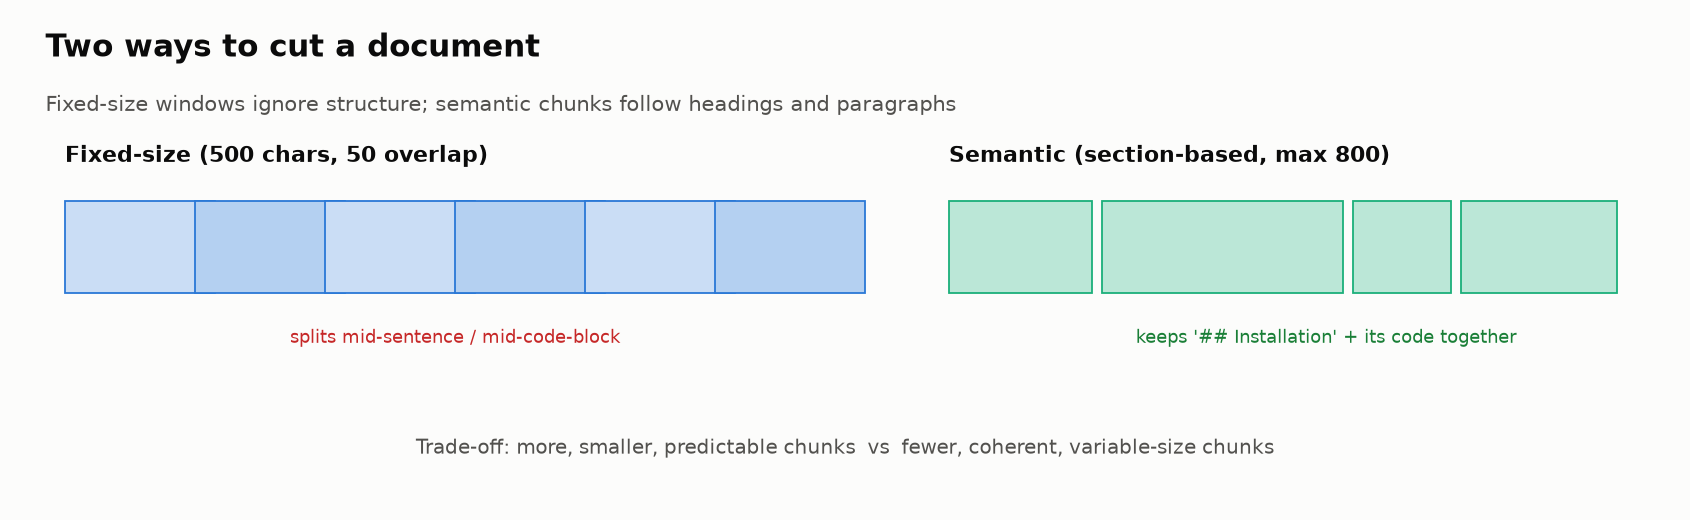

<sub>🖼️ *Fixed-size windows vs. structure-aware semantic chunks*</sub>

In [ ]:
# ============================================================
# CHUNKING STRATEGIES (span-based: every chunk remembers exactly where it came from)
# ============================================================
# Sizes are in TOKENS, estimated as characters / 4 (OpenAI's rule of thumb for English).
# Every chunk stores start/end character offsets into its document, so Task 6 can measure
# exactly how much answer-bearing text each chunk covers.

CHARS_PER_TOKEN = 4

@dataclass
class Chunk:
    """A single chunk: its text plus where it came from (doc + character span)."""
    id: str
    content: str
    doc_id: str
    doc_title: str
    chunk_index: int
    start_char: int
    end_char: int


def _make_chunks(doc, spans):
    text = DOC_TEXT[doc["id"]]
    return [Chunk(id=f"{doc['id']}_chunk_{i:03d}", content=text[s:e], doc_id=doc["id"],
                  doc_title=doc["title"], chunk_index=i, start_char=s, end_char=e)
            for i, (s, e) in enumerate(spans) if text[s:e].strip()]


def fixed_size_chunking(documents, chunk_tokens=125, overlap_tokens=12):
    """Slide a fixed window across each document. Simple and predictable, but it cuts
    mid-sentence and mid-code-block. (Defaults ≈ 500 / 50 characters.)"""
    size, step = chunk_tokens * CHARS_PER_TOKEN, (chunk_tokens - overlap_tokens) * CHARS_PER_TOKEN
    chunks = []
    for doc in documents:
        n = len(DOC_TEXT[doc["id"]])
        spans = [(s, min(s + size, n)) for s in range(0, n, step)]
        spans = [sp for i, sp in enumerate(spans) if i == 0 or sp[1] > spans[i - 1][1]]  # drop pure-overlap tails
        chunks += _make_chunks(doc, spans)
    return chunks


def _split_points(text, start, end, sep):
    """Offsets where a piece may start: just after each separator inside [start, end)."""
    points, i = [start], text.find(sep, start)
    while 0 <= i < end:
        cut = i + len(sep) if sep.strip() in (".",) else i + 1   # keep headers with their section
        if start < cut < end:
            points.append(cut)
        i = text.find(sep, i + len(sep))
    return points + [end]


def _recursive_spans(text, start, end, max_chars, seps):
    if end - start <= max_chars:
        return [(start, end)]
    for k, sep in enumerate(seps):
        points = _split_points(text, start, end, sep)
        if len(points) <= 2:
            continue                                    # this separator doesn't occur here; try a finer one
        spans, cur = [], points[0]
        for a, b in zip(points[:-1], points[1:]):       # greedily pack pieces up to max_chars
            if b - cur > max_chars and a > cur:
                spans.append((cur, a)); cur = a
        spans.append((cur, end))
        out = []
        for s, e in spans:                              # pieces that are still too big: recurse finer
            out += _recursive_spans(text, s, e, max_chars, seps[k + 1:]) if e - s > max_chars else [(s, e)]
        return out
    return [(s, min(s + max_chars, end)) for s in range(start, end, max_chars)]   # last resort: hard cut


def recursive_chunking(documents, chunk_tokens=200):
    """Recursive splitting (the idea behind LangChain's RecursiveCharacterTextSplitter):
    try section breaks first, then paragraphs, then lines, then sentences, then words,
    and only cut finer when a piece is still too big. No overlap."""
    seps = ["\n## ", "\n\n", "\n", ". ", " "]
    chunks = []
    for doc in documents:
        text = DOC_TEXT[doc["id"]]
        chunks += _make_chunks(doc, _recursive_spans(text, 0, len(text), chunk_tokens * CHARS_PER_TOKEN, seps))
    return chunks


def semantic_chunking(documents, max_tokens=200):
    """Structure-aware: one chunk per markdown section (## heading), split further only
    if a section is longer than max_tokens."""
    chunks = []
    for doc in documents:
        text = DOC_TEXT[doc["id"]]
        sections = _split_points(text, 0, len(text), "\n## ")
        spans = []
        for s, e in zip(sections[:-1], sections[1:]):
            spans += _recursive_spans(text, s, e, max_tokens * CHARS_PER_TOKEN, ["\n\n", "\n", ". ", " "])
        chunks += _make_chunks(doc, spans)
    return chunks


def describe(chunks):
    lens = [len(c.content) // CHARS_PER_TOKEN for c in chunks]
    return f"{len(chunks):3d} chunks, ~{np.mean(lens):.0f} tokens avg (min {min(lens)}, max {max(lens)})"


fixed_chunks = fixed_size_chunking(DOCUMENTS)          # ≈ 500 chars, 50 overlap: a classic tutorial default
semantic_chunks = semantic_chunking(DOCUMENTS)         # one chunk per section
print("✅ Created chunks using two strategies:")
print(f"   Fixed-size (125 tok, 12 overlap): {describe(fixed_chunks)}")
print(f"   Semantic (by section):            {describe(semantic_chunks)}")

In [ ]:
# Compare the first chunk of doc-001 under each strategy
for name, chunks in [("FIXED-SIZE", fixed_chunks), ("SEMANTIC", semantic_chunks)]:
    first = [c for c in chunks if c.doc_id == "doc-001"][0]
    print(f"── {name}: {first.id} · chars {first.start_char}–{first.end_char} ({len(first.content)} chars) ──")
    print(first.content[:300], "...\n")

### Checkpoint ✅
### Expected Output
```
✅ Created chunks using two strategies:
   Fixed-size (125 tok, 12 overlap):  26 chunks, ~107 tokens avg (min 18, max 125)
   Semantic (by section):             48 chunks, ~53 tokens avg (min 5, max 134)
```
Notice the fixed-size chunk of doc-001 ends mid-code-block, while the semantic chunk ends at a section boundary.

> 🔮 **Predict (write it down):** fixed-size vs. semantic, which will have the better **Recall@5**? The better **evidence recall**? Which sends **fewer tokens** to the LLM?

➡️ **Bridge:** chunks are just text until they're searchable; next, index them for meaning and for keywords.

---

## 🗄️ Task 4: Set Up the Vector Store

### Goal
Create a vector store behind a four-method adapter and ingest both chunk sets with embeddings.

### Three ways to search
| Mode | How it ranks chunks | Strong at | Weak at |
|---|---|---|---|
| **Dense** | embed question and chunks with the same model; rank by cosine similarity | paraphrases | exact identifiers; look-alike distractors |
| **BM25** (sparse: keyword counts) | score shared words, weighting rare words up and long chunks down | exact terms (`BP-4031`, `--rerun-failed`) | paraphrases that share no words |
| **Hybrid** | run both; merge the rankings with **Reciprocal Rank Fusion (RRF)**, score = Σ 1 / (60 + rank). Ranks only, so the two score scales never need reconciling | both styles | two searches |

An **embedding** is a list of numbers (384 here) a model assigns to a text so that similar meanings point in similar directions; **cosine similarity** measures how closely two of them align (1 = same direction, 0 = unrelated). It measures topical closeness, not whether a chunk *answers* the question, which is why look-alike distractors fool it.

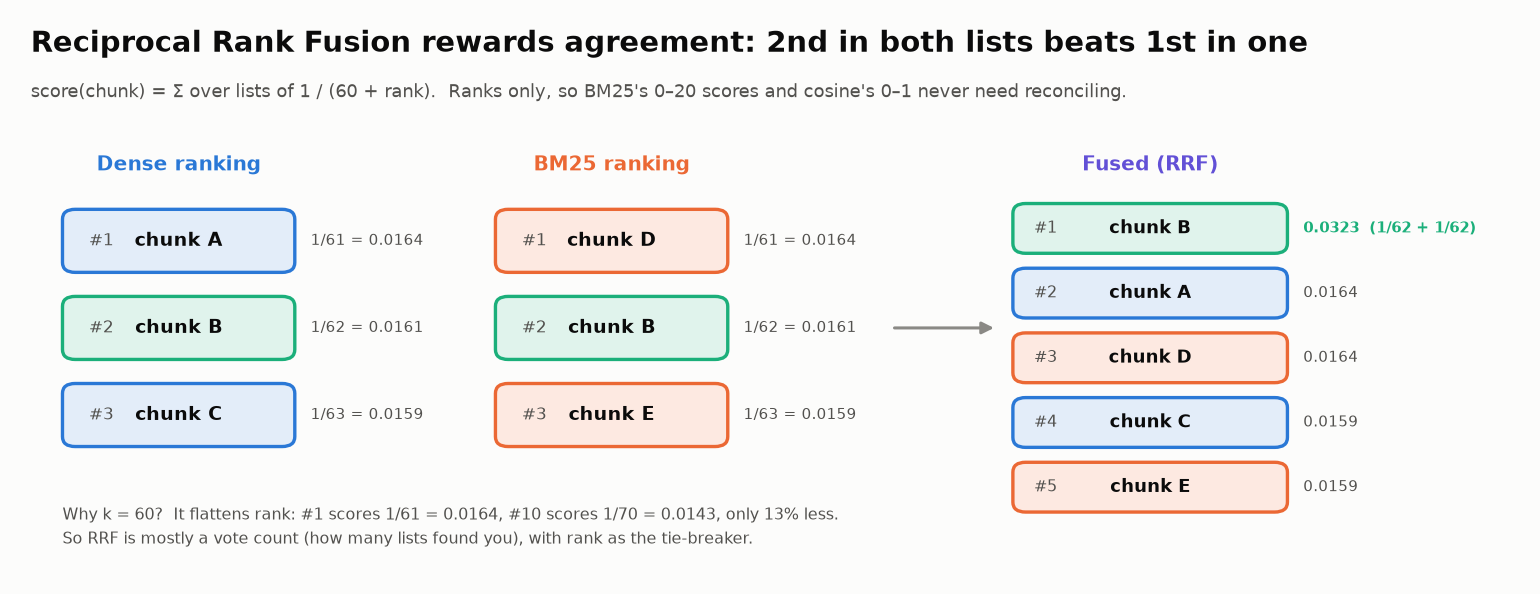

<sub>🖼️ *RRF is mostly a vote count: with k = 60, rank #1 scores only 13% more than rank #10, but appearing in both lists doubles your score*</sub>

### Two backends, one interface
| Backend | When | Search modes |
|---|---|---|
| **In-memory** (default) | Always works, instant, offline | all three, in ~60 lines of numpy |
| **Embedded Weaviate** (`USE_WEAVIATE = True`) | You want a real vector DB with native hybrid search | `near_vector`, `bm25`, `hybrid` (rank fusion) |

> 🧩 **Production pattern: a thin storage adapter.** All database calls go through `recreate`, `insert`, `count`, `search`, so you can swap vector databases (Weaviate, pgvector, Qdrant, OpenSearch...) without touching evaluation code.

> ⚠️ **Why Weaviate is optional (verified Nov 2026, `weaviate-client` 4.24):** embedded mode downloads a ~150 MB server binary on first run (~2.5 min on a home connection) and needs network access. It turns **read-only** when the disk is over 90% full ("store is read-only due to: resource pressure"), common on laptops, so the adapter raises that threshold. If anything fails, the lab falls back to the in-memory store. Weaviate's BM25 tokenizer differs slightly, so its hybrid numbers can shift.

In [ ]:
# ============================================================
# THE VECTOR STORE: one tiny interface, two backends
# ============================================================
# Every database call goes through: recreate(name) · insert(name, objects, vectors) · count(name)
#                                   · search(name, query_text, query_vector, k, mode)
# mode = "dense" (vector similarity) | "bm25" (keyword) | "hybrid" (both, fused with RRF)
#
# Default backend: InMemoryStore (numpy cosine + a 20-line BM25). Runs anywhere, instantly, offline.
# Optional backend: embedded Weaviate (set USE_WEAVIATE = True in Task 1). Same interface, real DB.

TOKEN_RE = re.compile(r"[a-z0-9]+(?:[-_.][a-z0-9]+)*")

def bm25_tokens(text):
    """Lowercase word tokens that keep identifiers like 'bp-4031' and 'rerun-failed' intact."""
    return TOKEN_RE.findall(text.lower())


def rrf_fuse(rankings, k=60):
    """Reciprocal Rank Fusion: score(item) = Σ 1 / (k + rank). Uses ranks only, so the
    incompatible score scales of BM25 and cosine similarity don't matter."""
    scores = defaultdict(float)
    for ranking in rankings:
        for rank, idx in enumerate(ranking, start=1):
            scores[idx] += 1.0 / (k + rank)
    return sorted(scores, key=lambda i: -scores[i])


class InMemoryStore:
    """Brute-force cosine search + Okapi BM25 in numpy. Fine up to ~100k chunks."""
    backend = "in-memory (numpy + BM25)"

    def __init__(self):
        self.cols = {}

    def recreate(self, name):
        self.cols[name] = {"objects": [], "vectors": None, "tokens": []}

    def insert(self, name, objects, vectors):
        col = self.cols[name]
        v = np.asarray(vectors, dtype=float)
        v = v / np.linalg.norm(v, axis=1, keepdims=True)
        col["objects"] += list(objects)
        col["vectors"] = v if col["vectors"] is None else np.vstack([col["vectors"], v])
        col["tokens"] += [bm25_tokens(o.get("search_text", o["content"])) for o in objects]
        toks = col["tokens"]                                   # refresh BM25 statistics
        col["df"] = Counter(t for doc in toks for t in set(doc))
        col["avgdl"] = np.mean([len(d) for d in toks])

    def count(self, name):
        return len(self.cols[name]["objects"])

    def _bm25(self, col, query, k1=1.5, b=0.75):
        n = len(col["tokens"])
        q = bm25_tokens(query)
        scores = np.zeros(n)
        for i, doc in enumerate(col["tokens"]):
            tf = Counter(doc)
            for t in q:
                if t in tf:
                    idf = np.log(1 + (n - col["df"][t] + 0.5) / (col["df"][t] + 0.5))
                    scores[i] += idf * tf[t] * (k1 + 1) / (tf[t] + k1 * (1 - b + b * len(doc) / col["avgdl"]))
        return scores

    def search(self, name, query_text, query_vector, k, mode="dense"):
        col = self.cols[name]
        q = np.asarray(query_vector, dtype=float); q = q / np.linalg.norm(q)
        sims = col["vectors"] @ q
        dense_rank = list(np.argsort(-sims))
        if mode == "dense":
            order = dense_rank
        elif mode == "bm25":
            bm = self._bm25(col, query_text)
            order = list(np.argsort(-bm, kind="stable"))
        elif mode == "hybrid":
            bm = self._bm25(col, query_text)
            order = rrf_fuse([dense_rank, list(np.argsort(-bm, kind="stable"))])
        else:
            raise ValueError(mode)
        return [{"id": f"{name}-{i}", "score": float(sims[i]), **col["objects"][i]} for i in order[:k]]

    def close(self):
        pass


class WeaviateStore:
    """Embedded Weaviate (v4 client). Downloads a ~150 MB server binary on first use."""
    backend = "weaviate-embedded"

    def __init__(self):
        import tempfile, weaviate
        self.wv = weaviate
        self.client = weaviate.connect_to_embedded(
            persistence_data_path=os.path.join(tempfile.gettempdir(), "weaviate-lab04b"),
            environment_variables={"LOG_LEVEL": "error",
                                   # Weaviate turns read-only when the disk is >90% full. Laptops often are.
                                   "DISK_USE_READONLY_PERCENTAGE": "100", "DISK_USE_WARNING_PERCENTAGE": "100"})

    def recreate(self, name):
        from weaviate.classes.config import Configure, Property, DataType
        if self.client.collections.exists(name):
            self.client.collections.delete(name)
        props = [Property(name=p, data_type=DataType.TEXT) for p in ("content", "search_text", "doc_id", "doc_title", "chunk_id")]
        props += [Property(name=p, data_type=DataType.INT) for p in ("chunk_index", "start_char", "end_char")]
        self.client.collections.create(name, properties=props, vector_config=Configure.Vectors.self_provided())

    def insert(self, name, objects, vectors):
        col = self.client.collections.get(name)
        with col.batch.fixed_size(batch_size=100) as batch:
            for obj, vec in zip(objects, vectors):
                batch.add_object(properties={"search_text": obj["content"], **obj}, vector=[float(x) for x in vec])
        if col.batch.failed_objects:
            raise RuntimeError(f"{len(col.batch.failed_objects)} objects failed: {col.batch.failed_objects[0].message}")

    def count(self, name):
        return self.client.collections.get(name).aggregate.over_all(total_count=True).total_count

    def search(self, name, query_text, query_vector, k, mode="dense"):
        from weaviate.classes.query import MetadataQuery, HybridFusion
        col, vec = self.client.collections.get(name), [float(x) for x in query_vector]
        md = MetadataQuery(distance=True, score=True)
        if mode == "dense":
            res = col.query.near_vector(near_vector=vec, limit=k, return_metadata=md)
        elif mode == "bm25":
            res = col.query.bm25(query=query_text, query_properties=["search_text"], limit=k, return_metadata=md)
        else:   # Weaviate's native hybrid, with rank-based fusion (same idea as rrf_fuse)
            res = col.query.hybrid(query=query_text, vector=vec, alpha=0.5, query_properties=["search_text"],
                                   fusion_type=HybridFusion.RANKED, limit=k, return_metadata=md)
        out = []
        for o in res.objects:
            d = o.metadata.distance
            out.append({"id": str(o.uuid), "score": 1 - d if d is not None else float(o.metadata.score or 0), **o.properties})
        return out

    def close(self):
        self.client.close()


def make_store():
    if USE_WEAVIATE:
        try:
            s = WeaviateStore()
            print(f"✅ Embedded Weaviate is ready: {s.client.is_ready()}")
            return s
        except Exception as e:
            print(f"⚠️  Embedded Weaviate unavailable ({type(e).__name__}: {str(e)[:120]})")
            print("   Falling back to the in-memory store. Every later cell works the same way.")
    return InMemoryStore()


store = make_store()
print(f"🗄️  Vector store backend: {store.backend}")

In [ ]:
# ============================================================
# EMBEDDING MODEL
# ============================================================
# all-MiniLM-L6-v2: small (384-dim), fast on CPU, free, still the sentence-transformers showcase model.
# In production you'd compare it against an API model (e.g. OpenAI text-embedding-3-small) on YOUR eval set.
# If the model can't be downloaded (no internet), we fall back to a TF-IDF + SVD embedder so every
# later cell still runs; the numbers will differ from the Expected Output blocks.
try:
    embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    EMBEDDER = "all-MiniLM-L6-v2"

    def embed_texts(texts):
        return embedding_model.encode(list(texts), show_progress_bar=False, normalize_embeddings=True)
except Exception as e:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    print(f"⚠️ Could not load MiniLM ({type(e).__name__}); using a TF-IDF + SVD fallback embedder.")
    _paras = [p for d in DOCUMENTS for p in d["content"].split("\n\n") if p.strip()]
    _tfidf = TfidfVectorizer(sublinear_tf=True).fit(_paras)
    _svd = TruncatedSVD(n_components=48, random_state=0).fit(_tfidf.transform(_paras))
    EMBEDDER = "tfidf-svd (fallback)"

    def embed_texts(texts):
        v = _svd.transform(_tfidf.transform(list(texts)))
        return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)

EMBEDDING_DIM = embed_texts(["probe"]).shape[1]
print(f"✅ Embedding model: {EMBEDDER} ({EMBEDDING_DIM}-dim)")

In [ ]:
# The two collections we compare in Task 6. Each object stores content, source doc and character span.
# We supply our OWN vectors, so the database does no embedding itself.
print("📥 Ingesting...")

In [ ]:
# ============================================================
# INGEST CHUNKS INTO THE VECTOR STORE
# ============================================================
# 1. Choose the text to index (the chunk itself, or the chunk with a context header; see Task 8)
# 2. Embed it   3. Store objects + vectors   4. VERIFY the count (never assume a batch write worked)
CHUNKS_BY_COLLECTION = {}

def section_of(chunk):
    """The nearest '## ' heading above the chunk (used for contextual headers in Task 8)."""
    text = DOC_TEXT[chunk.doc_id][:chunk.start_char + 1]
    heads = re.findall(r"\n## ([^\n]+)", "\n" + text)
    return heads[-1] if heads else ""

def ingest_chunks(chunks, collection_name, contextual=False, verbose=True):
    """Embed and store chunks. contextual=True prepends 'doc title > section' to the indexed text."""
    store.recreate(collection_name)
    search_texts = [f"{c.doc_title} > {section_of(c)}\n{c.content}" if contextual else c.content for c in chunks]
    vectors = embed_texts(search_texts)
    objects = [{"content": c.content, "search_text": st, "doc_id": c.doc_id, "doc_title": c.doc_title,
                "chunk_id": c.id, "chunk_index": c.chunk_index, "start_char": c.start_char, "end_char": c.end_char}
               for c, st in zip(chunks, search_texts)]
    store.insert(collection_name, objects, vectors)
    actual = store.count(collection_name)
    assert actual == len(chunks), f"expected {len(chunks)} objects, found {actual}"
    CHUNKS_BY_COLLECTION[collection_name] = chunks
    if verbose:
        print(f"   ✅ Ingested {actual} chunks into {collection_name}")

ingest_chunks(fixed_chunks, "FixedChunks")
ingest_chunks(semantic_chunks, "SemanticChunks")

### Checkpoint ✅
### Expected Output
```
🗄️  Vector store backend: in-memory (numpy + BM25)
✅ Embedding model: all-MiniLM-L6-v2 (384-dim)
📥 Ingesting...
   ✅ Ingested 26 chunks into FixedChunks
   ✅ Ingested 48 chunks into SemanticChunks
```
With `USE_WEAVIATE = True` the first line reads `✅ Embedded Weaviate is ready: True` / `🗄️ Vector store backend: weaviate-embedded`.

➡️ **Bridge:** both indexes are loaded. Ask them a question.

---

## 🔍 Task 5: Implement the Retrieval Pipeline

### Goal
Build `retrieve(query, collection, top_k, mode)`: embed the query with the **same** model as the chunks (a different model puts them in a different vector space), search, and return the top-K chunks with their source spans.

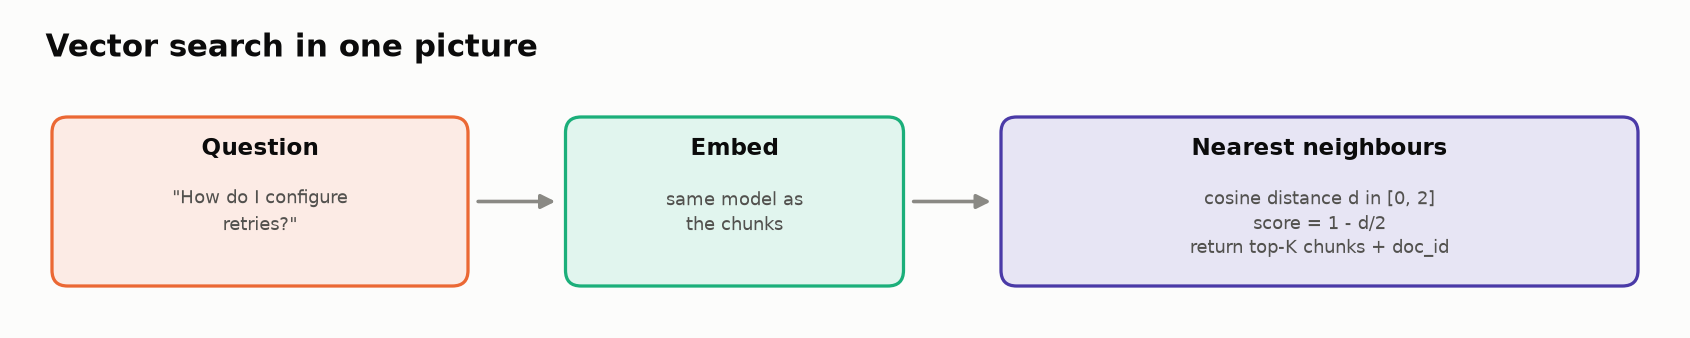

<sub>🖼️ *Retrieval = embed the question with the same model, then nearest-neighbour search*</sub>

In [ ]:
# ============================================================
# RETRIEVAL FUNCTION
# ============================================================
@dataclass
class RetrievalResult:
    """One retrieved chunk: text, source and position (for evaluation), and a score (higher = better)."""
    chunk_id: str
    content: str
    doc_id: str
    doc_title: str
    start_char: int
    end_char: int
    score: float


def retrieve(query, collection_name, top_k=5, mode="dense"):
    """Embed the query with the SAME model as the chunks, then search the store.
    mode: "dense" (vectors), "bm25" (keywords) or "hybrid" (both, fused)."""
    qvec = embed_texts([query])[0]
    hits = store.search(collection_name, query, qvec, top_k, mode=mode)
    return [RetrievalResult(h["chunk_id"], h["content"], h["doc_id"], h["doc_title"],
                            int(h["start_char"]), int(h["end_char"]), h["score"]) for h in hits]


test_query = "How do I install BrookPipe?"
print(f"Query: {test_query}")
for name in ["FixedChunks", "SemanticChunks"]:
    print(f"\n--- {name} ---")
    for i, r in enumerate(retrieve(test_query, name, top_k=3), 1):
        print(f"{i}. [{r.score:.3f}] {r.doc_title} ({r.doc_id}, chars {r.start_char}–{r.end_char})")
        print(f"   {r.content[:90].strip()!r}")

### Checkpoint ✅
You should see three results per collection. For "How do I install BrookPipe?", the fixed-size collection ranks the *Configuration Guide* and the *1.x migration guide* above *Getting Started*; the semantic collection puts the `## Installation` section first. Distractors and chunk boundaries already matter.

### Expected Output (partial)
```
--- FixedChunks ---
1. [0.591] BrookPipe Configuration Guide (doc-002, chars 0–500)
2. [0.539] Migrating from BrookPipe 1.x to 2.0 (doc-007, chars 0–500)
3. [0.505] Getting Started with BrookPipe (doc-001, chars 0–500)

--- SemanticChunks ---
1. [0.696] Getting Started with BrookPipe (doc-001, chars 161–243)
...
```

➡️ **Bridge:** one question shows a symptom. Task 6 measures all 14, through two different lenses.

---

## 📊 Task 6: Evaluate Retrieval Quality (documents vs. evidence)

### Goal
Score both chunkers twice: with **document-level** metrics (Recall@5, Precision@5, nDCG@5, MRR) and with **evidence-level** metrics (answer found, IoU, tokens sent). Definitions are in the 📏 primer.

### Why both?
Document-level metrics ask whether a chunk from the right *document* showed up. Evidence-level metrics ask whether the *sentence that answers the question* reached the LLM, and how much padding came with it. Chroma's 2024 chunking study argued that only the second kind can compare chunkers.

> 🔮 **Predict:** both strategies will reach the right document in the top 5 for (nearly) every question. Will their evidence metrics also be (nearly) equal?

In [ ]:
# ============================================================
# RETRIEVAL METRICS: document level AND token (evidence) level
# ============================================================
# Document level (on the ranked list of retrieved CHUNKS, each mapped to its source doc):
def compute_recall_at_k(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Recall@K: share of relevant DOCUMENTS that appear anywhere in the top K chunks."""
    return len(set(retrieved_doc_ids[:k]) & set(relevant_doc_ids)) / len(set(relevant_doc_ids))

def compute_precision_at_k(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Precision@K: share of the top K CHUNKS that come from a relevant document."""
    return sum(d in relevant_doc_ids for d in retrieved_doc_ids[:k]) / k

def compute_ndcg_at_k(retrieved_doc_ids, relevant_doc_ids, k=5, n_relevant_available=None):
    """nDCG@K over chunks: relevant chunks near the top score more. Ideal = all relevant chunks first."""
    dcg = sum(1.0 / np.log2(i + 2) for i, d in enumerate(retrieved_doc_ids[:k]) if d in relevant_doc_ids)
    n_ideal = min(k, n_relevant_available if n_relevant_available is not None else k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(n_ideal))
    return dcg / idcg if idcg else 0.0

def compute_mrr(retrieved_doc_ids, relevant_doc_ids, k=5):
    """Reciprocal rank of the first chunk from a relevant document (0 if none in the top K)."""
    return next((1.0 / r for r, d in enumerate(retrieved_doc_ids[:k], 1) if d in relevant_doc_ids), 0.0)

# Token (evidence) level, following Chroma's chunking evaluation (2024), measured in characters:
#   evidence E = the exact answer-bearing spans; retrieved R = every character we send to the LLM
#   recall    = |R ∩ E| / |E|          did the answer actually reach the LLM?
#   precision = |R ∩ E| / |R|          how much of what we sent was answer? (duplicates from overlap count)
#   IoU       = |R ∩ E| / |R ∪ E|      one number that punishes both missing and padding
def evidence_metrics(results, evidence_spans):
    covered = 0
    for doc_id, s, e in evidence_spans:
        hit = np.zeros(e - s, dtype=bool)
        for r in results:
            if r.doc_id == doc_id:
                lo, hi = max(s, r.start_char), min(e, r.end_char)
                if hi > lo:
                    hit[lo - s:hi - s] = True
        covered += hit.sum()
    ev = sum(e - s for _, s, e in evidence_spans)
    sent = sum(r.end_char - r.start_char for r in results)
    return {"ev_recall": covered / ev, "ev_precision": covered / sent if sent else 0.0,
            "iou": covered / (sent + ev - covered), "tokens_sent": sent / CHARS_PER_TOKEN}

def answer_found(results, evidence_spans, min_cover=0.5):
    """1 if the top-K chunks cover at least half of the evidence text, else 0."""
    return float(evidence_metrics(results, evidence_spans)["ev_recall"] >= min_cover)

# Sanity checks: always test metric code on cases you can do by hand
assert compute_precision_at_k(["a", "b", "a", "c", "d"], ["a"], 5) == 0.4
assert compute_recall_at_k(["a", "b"], ["a", "z"], 5) == 0.5
assert compute_mrr(["b", "a"], ["a"]) == 0.5
_r = [RetrievalResult("x", "", "d", "", 0, 100, 1.0)]
assert evidence_metrics(_r, [("d", 50, 150)]) == {"ev_recall": 0.5, "ev_precision": 0.5, "iou": 50 / 150, "tokens_sent": 25.0}
print("✅ Retrieval metric functions defined (and sanity-checked)")

In [ ]:
def n_relevant_chunks(collection_name, relevant_doc_ids):
    """How many chunks in this collection come from a relevant document? (for ideal DCG)"""
    return sum(ch.doc_id in relevant_doc_ids for ch in CHUNKS_BY_COLLECTION[collection_name])

def evaluate_retrieval(collection_name, evaluation_dataset, k=5, mode="dense", retriever=None):
    """Per-question document-level and evidence-level metrics for one collection + search mode."""
    rows = []
    for item in evaluation_dataset:
        res = retriever(item["question"], k) if retriever else retrieve(item["question"], collection_name, k, mode)
        ids, rel = [r.doc_id for r in res], item["relevant_doc_ids"]
        rows.append({"question": item["question"][:48], "style": item["style"],
                     "recall@k": compute_recall_at_k(ids, rel, k), "precision@k": compute_precision_at_k(ids, rel, k),
                     "ndcg@k": compute_ndcg_at_k(ids, rel, k, n_relevant_chunks(collection_name, rel)),
                     "mrr": compute_mrr(ids, rel, k), "answer_found": answer_found(res, item["evidence_spans"]),
                     **evidence_metrics(res, item["evidence_spans"])})
    return pd.DataFrame(rows)

fixed_eval = evaluate_retrieval("FixedChunks", EVALUATION_DATASET, k=5)
semantic_eval = evaluate_retrieval("SemanticChunks", EVALUATION_DATASET, k=5)

In [ ]:
# ============================================================
# COMPARE: document level vs evidence level
# ============================================================
cols = ["recall@k", "precision@k", "ndcg@k", "mrr", "answer_found", "iou", "tokens_sent"]
comparison = pd.DataFrame({"Fixed-size": fixed_eval[cols].mean(), "Semantic": semantic_eval[cols].mean()})
print(comparison.to_string(float_format="%.3f"))

In [ ]:
# ── 🎨 Reveal: the same two strategies through two lenses ──
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
doc_cols, ev_cols = ["recall@k", "mrr"], ["answer_found", "iou"]
comparison.loc[doc_cols].plot(kind="bar", ax=axes[0], rot=0, legend=False, ylim=(0, 1.1))
axes[0].set_title("Document level: a tie")
(comparison.loc[ev_cols] / comparison.loc[ev_cols].max(axis=1).values[:, None]).plot(kind="bar", ax=axes[1], rot=0, ylim=(0, 1.1))
axes[1].set_title("Evidence level (relative to the better one): not a tie")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

f, s = comparison["Fixed-size"], comparison["Semantic"]
insight(
    f"Both strategies score Recall@5 = {f['recall@k']:.2f} vs {s['recall@k']:.2f}. The evidence metrics disagree by "
    f"{abs(f['answer_found'] - s['answer_found']):.0%} on answer-found and {max(f['iou'], s['iou']) / min(f['iou'], s['iou']):.1f}× on IoU",
    f"Fixed-size windows got the answer text to the LLM {f['answer_found']:.0%} of the time, sending ~{f['tokens_sent']:.0f} tokens per "
    f"question; semantic sections {s['answer_found']:.0%} of the time with ~{s['tokens_sent']:.0f}. That's a real trade-off (coverage vs. "
    "padding), and document-level recall is blind to it: with only 8 documents, touching the right *document* is easy.\n"
    "**Rule of thumb:** a metric that never moves can't help you decide. To compare chunkers, label the evidence span and "
    "measure whether *it* was retrieved, plus what it cost.",
    kind="surprise")

### Checkpoint ✅
### Expected Output
```
              Fixed-size  Semantic
recall@k           1.000     1.000
precision@k        0.429     0.471
ndcg@k             0.597     0.517
mrr                0.833     0.827
answer_found       0.929     0.786
iou                0.037     0.083
tokens_sent      574.482   257.804
```
Card: *"Both strategies score Recall@5 = 1.00 vs 1.00. The evidence metrics disagree by 14% on answer-found and 2.2× on IoU"*.

*(Decimals can shift slightly between embedding-model versions; the pattern is what matters.)*

### 🔍 Why is every IoU so small?
IoU can't exceed evidence ÷ characters sent. Evidence spans average ~90 characters; fixed-size chunks send ~2,300 per question (574 tokens × 4), a **ceiling of ≈ 0.04**, and they scored 0.037. Semantic chunks send ~1,030: ceiling ≈ 0.087, scored 0.083. Both sit near their ceiling, so at K = 5 IoU is almost purely a **padding meter**: compare it across configs, never against 1.0.

![Comic, four panels. The PM celebrates a screen reading 'Recall@5 100%': every question hit the right doc. The engineer asks whether the answer itself reached the model; the PM: 'It reached the right document.' A customer asks how to set retries; the model, holding page 2 of the Error Handling guide, cheers: 'Right guide! The answer's on page 1.' Caption: recall checks the address, not the package. The auditor, next to a screen reading 'Answer found 79%': 'Label the evidence span. Then measure.'](attachment:comic-address.png)

<sub>🖼️ *Recall@K confirms delivery to the right building. Answer found checks whether the package arrived.*</sub>

### 🤔 Analyze
1. Semantic chunks have the better IoU but the worse answer found. Which would you rather have for a support bot? For a compliance bot?
2. Fixed-size chunks were ~125 tokens, semantic ~53. Is this comparison about *strategy* or about *size*? Task 7 separates the two.

➡️ **Bridge:** two configurations aren't a decision. Next, sweep chunk size and strategy the way Chroma did.

---
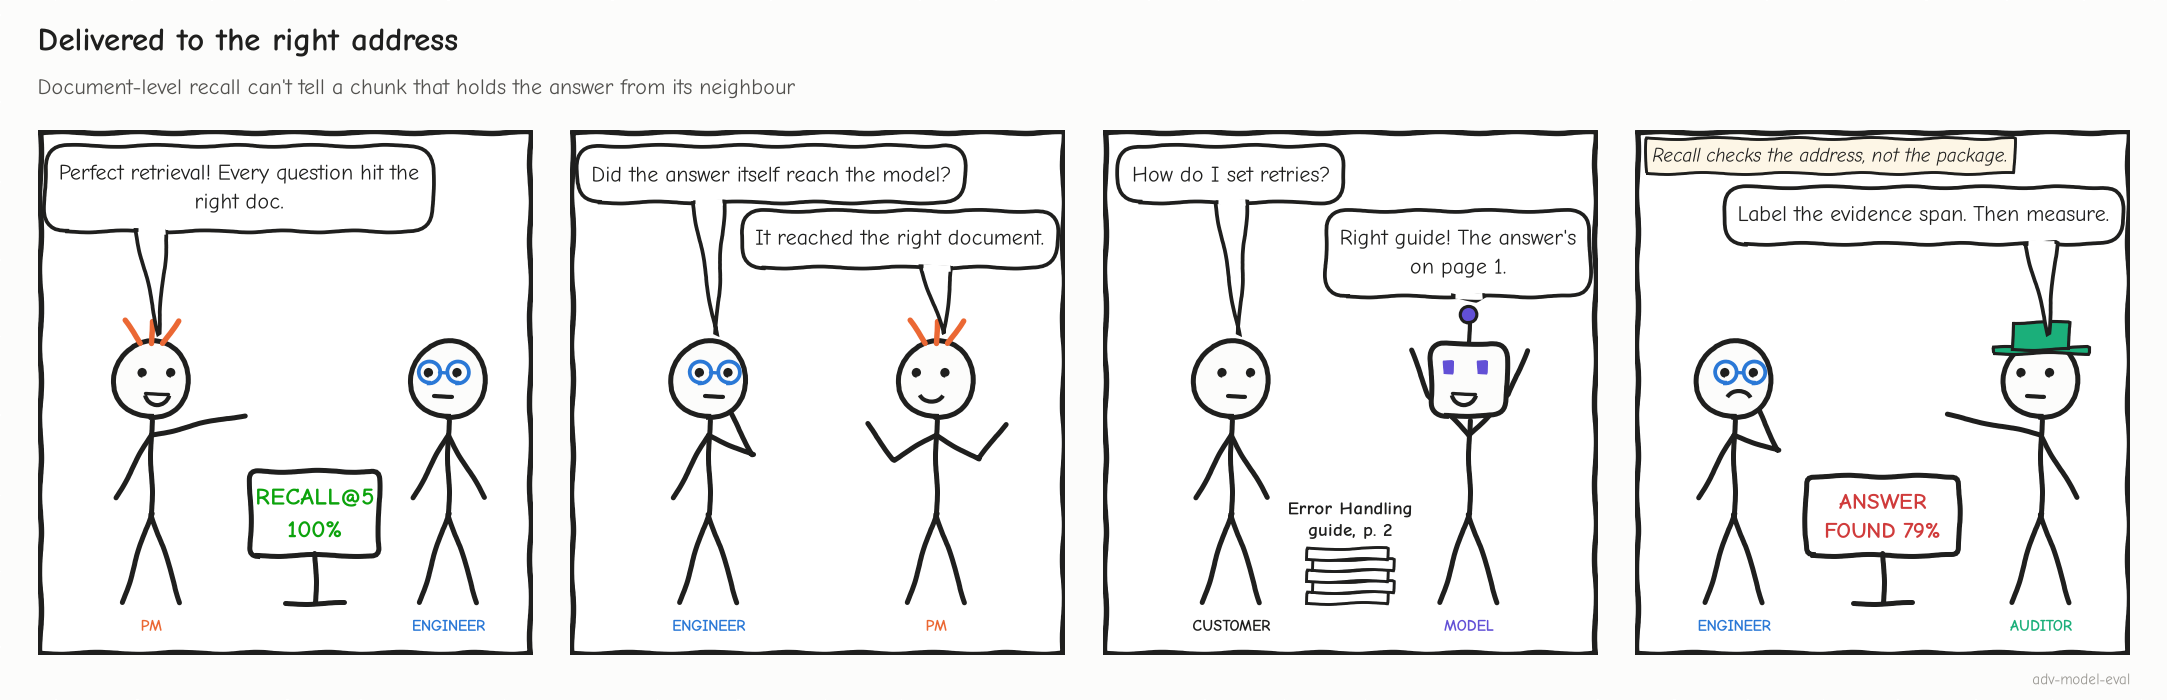

## 📐 Task 7: Chunk-Size Sweep: Measure It on Your Corpus

### Goal
Evaluate 8 chunking configurations with the same questions, embedder and K, and pick one with evidence.

### 🎯 Why This Matters
Chroma's technical report *Evaluating Chunking Strategies for Retrieval* (Jul 2024) scored chunkers with token-level recall, precision and IoU instead of document hit rates (they report percentages; this lab reports fractions). Two findings you'll test:
- **OpenAI's default file-search chunking (800 tokens, 400 overlap) scored lowest on most metrics** (IoU 1.4).
- A **recursive splitter at 200 tokens with no overlap was strong** (recall 88.1, IoU 6.9). Removing overlap generally improved IoU and precision (though with a weaker embedder, overlap helped recall).

Their caveat applies to you too: a small, LLM-generated dataset.

> 🔮 **Predict:** which config will have the **worst IoU**? Will the 800/400 default have the best or worst *answer found*?

### Steps
1. Run the sweep (≈ 30 s: 8 re-indexes of a tiny corpus)
2. Read the cost-vs-benefit chart and the card

In [ ]:
# ============================================================
# CHUNK-SIZE SWEEP: same corpus, same questions, same embedder, same K = 5
# ============================================================
SWEEP_CONFIGS = {
    "fixed 800 / 400 overlap": lambda: fixed_size_chunking(DOCUMENTS, 800, 400),   # OpenAI's file-search default
    "fixed 400 / 200 overlap": lambda: fixed_size_chunking(DOCUMENTS, 400, 200),
    "fixed 200 / 100 overlap": lambda: fixed_size_chunking(DOCUMENTS, 200, 100),
    "fixed 200 / no overlap":  lambda: fixed_size_chunking(DOCUMENTS, 200, 0),
    "recursive 400":           lambda: recursive_chunking(DOCUMENTS, 400),
    "recursive 200":           lambda: recursive_chunking(DOCUMENTS, 200),
    "recursive 100":           lambda: recursive_chunking(DOCUMENTS, 100),
    "semantic (sections)":     lambda: semantic_chunking(DOCUMENTS),
}
CORPUS_TOKENS = sum(len(t) for t in DOC_TEXT.values()) / CHARS_PER_TOKEN

sweep_rows, SWEEP_CHUNKS = [], {}
for name, make in SWEEP_CONFIGS.items():
    chunks = make()
    SWEEP_CHUNKS[name] = chunks
    ingest_chunks(chunks, "Sweep", verbose=False)
    ev = evaluate_retrieval("Sweep", EVALUATION_DATASET, k=5)
    sweep_rows.append({"config": name, "chunks": len(chunks), "doc_recall@5": ev["recall@k"].mean(),
                       "answer_found": ev["answer_found"].mean(), "iou": ev["iou"].mean(),
                       "tokens_sent": ev["tokens_sent"].mean()})
sweep_df = pd.DataFrame(sweep_rows).set_index("config")
print(sweep_df.to_string(float_format="%.3f"))

In [ ]:
# ── Reveal: cost (tokens per question) vs. benefit (answer found), one point per chunking config ──
fig, ax = plt.subplots(figsize=(10, 4.8))
LABEL_POS = {"recursive 400": ((-6, -16), "right"), "fixed 400 / 200 overlap": ((0, 12), "center"),   # the three
             "fixed 800 / 400 overlap": ((6, -16), "left")}                                                # at ~1,500 tokens
for (name, r), color in zip(sweep_df.sort_values("tokens_sent").iterrows(), PALETTE * 2):
    x, y = r["tokens_sent"], r["answer_found"]
    ax.scatter(x, y, s=60 + 2500 * r["iou"], color=color, alpha=0.85, zorder=3)
    offset, ha = LABEL_POS.get(name, ((8, 6), "left"))
    ax.annotate(name, (x, y), textcoords="offset points", xytext=offset, ha=ha, fontsize=9)
ax.set_xlabel("tokens sent to the LLM per question (K = 5)"); ax.set_ylabel("answer found (share of questions)")
ax.set_ylim(0.6, 1.08); ax.set_xlim(0, sweep_df["tokens_sent"].max() * 1.3)

good_enough = sweep_df[sweep_df["answer_found"] >= 0.9]
BEST_CONFIG = good_enough["tokens_sent"].idxmin() if len(good_enough) else sweep_df["answer_found"].idxmax()
best, default = sweep_df.loc[BEST_CONFIG], sweep_df.loc["fixed 800 / 400 overlap"]
ax.set_title(f"'{BEST_CONFIG}': {best.answer_found:.0%} answer found for {best.tokens_sent / default.tokens_sent:.0%} "
             "of the 800/400 default's tokens")
ax.text(0.99, 0.03, "bubble size = IoU", transform=ax.transAxes, ha="right", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

same_size = sweep_df.loc[["fixed 200 / no overlap", "recursive 200"]]
tiles([
    ("Doc-level Recall@5", f"{sweep_df['doc_recall@5'].min():.2f}–{sweep_df['doc_recall@5'].max():.2f}", "across all 8 configs", "warning"),
    ("Worst IoU", f"{sweep_df['iou'].min():.3f}", sweep_df["iou"].idxmin(), "critical"),
    ("Best IoU", f"{sweep_df['iou'].max():.3f}", sweep_df["iou"].idxmax(), "good"),
    ("Recommended", BEST_CONFIG, f"cheapest config with ≥ 90% answer found", "good"),
])
insight(
    f"The 800/400 default sends {default.tokens_sent:,.0f} tokens per question ({default.tokens_sent / CORPUS_TOKENS:.0%} of the "
    f"whole corpus) and has the worst IoU ({default.iou:.3f}); '{BEST_CONFIG}' finds the answer {best.answer_found:.0%} of the time "
    f"with {best.tokens_sent:,.0f}",
    f"On a corpus this small, whole-document chunks 'win' answer-found ({default.answer_found:.0%}) by smuggling most of the corpus "
    f"into every prompt; at real scale those 5 slots would be filled with noise. At the same 200-token size, splitting on "
    f"structure found the answer {same_size.loc['recursive 200', 'answer_found']:.0%} of the time vs "
    f"{same_size.loc['fixed 200 / no overlap', 'answer_found']:.0%} for blind fixed windows, while sending fewer tokens. "
    "Note what didn't move: document-level Recall@5 stays flat across every config.\n"
    "**Rule of thumb:** choose chunking with an evidence-level metric (answer found, IoU) *and* a token cost on your own "
    "corpus; never with document-level recall, and never by accepting a tool's default.")

### Checkpoint ✅
### Expected Output
```
                         chunks  doc_recall@5  answer_found   iou  tokens_sent
config
fixed 800 / 400 overlap       8         1.000         1.000 0.014     1606.464
fixed 400 / 200 overlap       9         1.000         1.000 0.014     1541.714
fixed 200 / 100 overlap      21         1.000         1.000 0.023      957.321
fixed 200 / no overlap       16         1.000         0.786 0.022      913.518
recursive 400                 9         1.000         1.000 0.015     1473.607
recursive 200                18         1.000         0.929 0.028      770.821
recursive 100                39         1.000         0.714 0.058      321.357
semantic (sections)          48         1.000         0.786 0.083      257.804
```
Chart title: *"'recursive 200': 93% answer found for 48% of the 800/400 default's tokens"*. Tiles: doc-level Recall@5 **1.00–1.00** · worst IoU **0.014** (fixed 800 / 400 overlap) · best IoU **0.083** (semantic) · recommended **recursive 200**.

### 🔍 What Just Happened?
Your corpus reproduced Chroma's two headline findings: the 800/400 default had the **worst IoU**, and **recursive 200 with no overlap** was the cheapest config that still found the answer at least 90% of the time. One result differs from Chroma's average: overlap *helped* at 200 tokens (answer found 100% with 100-token overlap vs 79% without, for ~5% more tokens). That's why you measure on your own corpus instead of copying anyone's recommendation, Chroma's included.

**Why does 800/400 never miss?** Every BrookPipe doc is shorter than 800 tokens (the longest is ~409), so each doc becomes one chunk and "top 5" means *send 5 of the 8 documents*. On a small corpus, big chunks always look safe; the bill and the distractors arrive at scale.

➡️ **Bridge:** chunking decides *what* can be found. Next: *how* you search. Is vector search alone enough?

---

## 🔀 Task 8: Hybrid Search, Context Headers and Reranking

### Goal
On the recommended chunking, compare five retrieval stacks on **retrieval-failure rate** (share of questions whose answer is *not* in the top K), and decide which layers earn their cost.

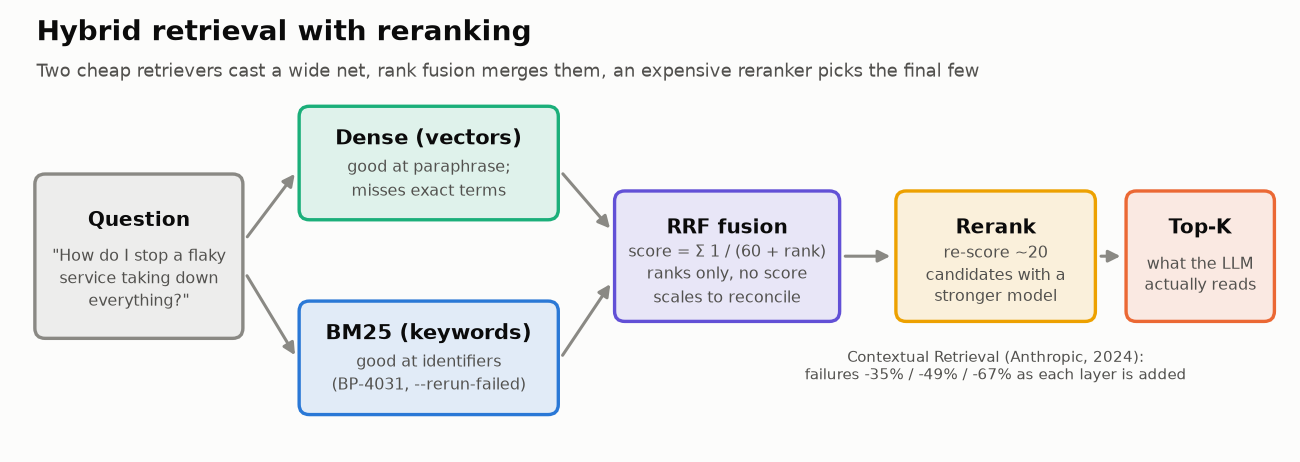

<sub>🖼️ *Two cheap retrievers cast a wide net, rank fusion merges them, an expensive reranker picks the final few*</sub>

| Layer | What it adds | Cost |
|---|---|---|
| **BM25** | keyword matching (Task 4) | ~free |
| **Hybrid (RRF)** | fuses the dense and BM25 rankings (Task 4) | ~free |
| **Context headers** | indexes each chunk as "doc title > section" + text, so a chunk that says "it" still knows what "it" is. A crude, free version of Anthropic's *Contextual Retrieval*, which has an LLM write that context | re-index once |
| **Rerank** | re-scores ~20 candidates with a slower, more careful model and keeps the best K: `maxsim` (scores a chunk by its best-matching sentence; offline) or a **cross-encoder** (reads question and chunk together in one model; optional. Dense search is a *bi-encoder*: it embeds them separately and compares two vectors) | latency per query |

**Why K = 2?** This index has only ~18 chunks, so at large K everything is retrieved and nothing can fail. A tight budget makes ranking matter, the way it does at K = 20 over millions of chunks. The table also reports your real `K_CONTEXT`.

> 🔮 **Predict:** order the five stacks from most to fewest failures. Will the reranker, the most expensive layer, help most?

In [ ]:
# ============================================================
# RERANKING: retrieve wide, then re-score the candidates more carefully
# ============================================================
# RERANKER = "maxsim"        (default, offline): split each candidate into sentences/lines, embed them,
#                            and score the chunk by its BEST-matching sentence. A long chunk with one
#                            perfect sentence beats a chunk that is vaguely similar overall.
# RERANKER = "cross-encoder" (optional): cross-encoder/ms-marco-MiniLM-L6-v2 reads (question, chunk)
#                            together. Usually the stronger reranker; downloads ~90 MB.
_ce = None
_sent_cache = {}

def _sentences(text):
    parts = re.split(r"(?<=[.!?:])\s+|\n+", text)
    return [p.strip(" -*#`") for p in parts if len(p.strip(" -*#`")) > 3] or [text]

def rerank(query, results, top_k):
    global _ce
    if RERANKER == "cross-encoder":
        if _ce is None:
            from sentence_transformers import CrossEncoder
            _ce = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")
        scores = _ce.predict([(query, r.content) for r in results])
    else:
        q = embed_texts([query])[0]
        scores = []
        for r in results:
            if r.chunk_id not in _sent_cache:
                _sent_cache[r.chunk_id] = embed_texts(_sentences(r.content))
            scores.append(float(np.max(_sent_cache[r.chunk_id] @ q)))
    order = np.argsort(-np.asarray(scores), kind="stable")[:top_k]
    return [results[i] for i in order]

def retrieve_and_rerank(query, collection_name, top_k=3, n_candidates=20, mode="hybrid"):
    """Two-stage retrieval: cheap wide recall (n_candidates), then precise reranking down to top_k."""
    return rerank(query, retrieve(query, collection_name, n_candidates, mode), top_k)

In [ ]:
# ============================================================
# COMPARE RETRIEVAL STACKS on the recommended chunking, at a tight and a looser context budget
# ============================================================
prod_chunks = SWEEP_CONFIGS[BEST_CONFIG]()
ingest_chunks(prod_chunks, "ProdChunks")                    # plain chunks
ingest_chunks(prod_chunks, "ProdChunksCtx", contextual=True)  # chunks indexed with "doc title > section" headers

STACKS = {
    "dense":                          lambda q, k: retrieve(q, "ProdChunks", k, "dense"),
    "BM25":                           lambda q, k: retrieve(q, "ProdChunks", k, "bm25"),
    "hybrid (RRF)":                   lambda q, k: retrieve(q, "ProdChunks", k, "hybrid"),
    "hybrid + context headers":       lambda q, k: retrieve(q, "ProdChunksCtx", k, "hybrid"),
    "hybrid + headers + rerank":      lambda q, k: retrieve_and_rerank(q, "ProdChunksCtx", k, n_candidates=20),
}
stack_rows, stack_detail = [], {}
for name, fn in STACKS.items():
    row = {"stack": name}
    for k in (2, K_CONTEXT):
        ev = evaluate_retrieval("ProdChunks", EVALUATION_DATASET, k=k, retriever=fn)
        row[f"failure@{k}"] = 1 - ev["answer_found"].mean()
        row[f"doc_mrr@{k}"] = ev["mrr"].mean()
        if k == 2:
            stack_detail[name] = ev
            for style in ("standard", "keyword", "paraphrase"):
                row[f"found@2 {style}"] = ev.loc[ev["style"] == style, "answer_found"].mean()
    stack_rows.append(row)
stacks_df = pd.DataFrame(stack_rows).set_index("stack")
print(stacks_df.to_string(float_format="%.2f"))

In [ ]:
# ── Reveal: the retrieval-failure staircase at K = 2 ──
fail2 = stacks_df["failure@2"]
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(range(len(fail2)), fail2.values, color=[PALETTE[0]] * len(fail2), width=0.6)
best_stack = fail2.idxmin()
bars[list(fail2.index).index(best_stack)].set_color(PALETTE[2])
for i, v in enumerate(fail2.values):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=11, weight="bold")
ax.set_xticks(range(len(fail2))); ax.set_xticklabels([s.replace(" + ", "\n+ ") for s in fail2.index], fontsize=9.5)
ax.set_ylabel("retrieval failure rate @2\n(answer NOT in the 2 chunks)"); ax.set_ylim(0, max(fail2) + 0.1)
base = fail2["dense"]
ax.set_title(f"Hybrid + context headers cut failures {1 - fail2['hybrid + context headers'] / base:.0%} vs dense; "
             f"reranking changed it by {100 * (fail2['hybrid + headers + rerank'] - fail2['hybrid + context headers']):+.0f} pts")
plt.tight_layout(); plt.show()

d = stacks_df
rr_delta = fail2["hybrid + headers + rerank"] - fail2["hybrid + context headers"]
rr_text = ("did not earn its cost on this corpus" if rr_delta >= 0 else
           f"cut failures by a further {-rr_delta:.0%} pts, so it earned its place here")
insight(
    f"Dense alone missed the answer {base:.0%} of the time at K = 2; '{best_stack}' missed {fail2[best_stack]:.0%} "
    f"({1 - fail2[best_stack] / base:.0%} fewer failures). Then the reranker made it {fail2['hybrid + headers + rerank']:.0%}",
    f"Dense and BM25 fail on *different* questions: dense found {d.loc['dense', 'found@2 paraphrase']:.0%} of paraphrased questions "
    f"but only {d.loc['dense', 'found@2 standard']:.0%} of the standard ones (distractor docs crowded it out); BM25 found "
    f"{d.loc['BM25', 'found@2 standard']:.0%} of standard ones and {d.loc['BM25', 'found@2 paraphrase']:.0%} of paraphrases. Fusion "
    f"recovers much of both ({d.loc['hybrid (RRF)', 'found@2 standard']:.0%} standard, {d.loc['hybrid (RRF)', 'found@2 paraphrase']:.0%} paraphrase). "
    f"The '{RERANKER}' reranker, a published best practice, {rr_text}. "
    f"At K = {K_CONTEXT} the stacks are much closer (failure@{K_CONTEXT}: {d[f'failure@{K_CONTEXT}'].min():.0%}–{d[f'failure@{K_CONTEXT}'].max():.0%}): "
    "the more chunks you pass, the less ranking matters.\n"
    "**Rule of thumb:** add each retrieval layer as an A/B test against the plain dense baseline on *your* eval set, at the K "
    "you actually use. Keep a layer only if it beats noise (here n = 14, so one question = 7 points).",
    kind="surprise")
insight(
    "Anthropic's Contextual Retrieval (Sep 2024): the same staircase, measured at scale",
    "Failure = relevant documents missing from the top 20 chunks (1 − recall@20): baseline 5.7%; contextual embeddings 3.7% "
    "(**−35%**); + contextual BM25 2.9% (**−49%**); + reranking ~150 candidates down to 20, 1.9% (**−67%**). "
    "Their contextual step has an LLM write each chunk's context; your title-and-section header is the free, crude version. "
    "The caution, from Elastic's experiments on BEIR (a standard suite of public retrieval datasets, 2023): hybrid beat BM25 by "
    "~18% nDCG@10 but a learned sparse retriever by only ~1.4%, so gains are relative to your baseline and corpus.",
    kind="research")

### Checkpoint ✅
### Expected Output (default `RERANKER = "maxsim"`, in-memory store)
```
                           failure@2  doc_mrr@2  found@2 standard  found@2 keyword  found@2 paraphrase  failure@3  doc_mrr@3
stack
dense                           0.43       0.79              0.40             1.00                1.00       0.14       0.81
BM25                            0.21       0.82              0.90             1.00                0.00       0.21       0.82
hybrid (RRF)                    0.21       0.82              0.80             1.00                0.50       0.14       0.82
hybrid + context headers        0.14       0.86              0.90             1.00                0.50       0.14       0.86
hybrid + headers + rerank       0.21       0.75              0.80             1.00                0.50       0.14       0.75
```
Chart title: *"Hybrid + context headers cut failures 67% vs dense; reranking changed it by +7 pts"*. Two cards: 🤯 the staircase and the reranker surprise; 📚 Anthropic's Contextual Retrieval numbers.

> 🔁 **Try it:** set `RERANKER = "cross-encoder"` in Task 1 and re-run Tasks 8–11. The cross-encoder pushes document-level MRR to **1.00** (the top chunk always comes from the right document) yet failure@2 stays at **21%**: it picks the right document's *wrong* chunk. Optimizing the metric you can see isn't the same as optimizing the one you need.

### 🔍 What Just Happened?
Dense and keyword search fail on **different** questions, so fusing them helps; giving chunks their title and section helps more. Your corpus reproduced the first steps of Anthropic's staircase and broke it at the reranker.

**Why did the reranker hurt?** `maxsim` scores a chunk by its single best sentence. For question 8 ("What is a Pipeline in BrookPipe?") it promoted *Performance Optimization*, whose opener "Optimize your BrookPipe pipelines for speed and efficiency" echoes the question's words, over the *Key Concepts* list that holds the definition. Echoing the question is not answering it.

Both the 43% → 14% staircase and the reranker's +7 points rest on a handful of questions. 🌶️🌶️ Challenge 2 tests whether either is real.

➡️ **Bridge:** retrieval is decided. Now generate answers, and see what long-context research says about simply stuffing in more text.

---

## 🤖 Task 9: Implement the Generation Pipeline

### Goal
Complete the pipeline: retrieve with the best stack from Task 8, assemble context with source titles, and generate.

| `PROVIDER` | Generator | Notes |
|---|---|---|
| `"mock"` (default) | extractive: returns the 2 context sentences most similar to the question | offline, free, reproducible, faithful **by construction** |
| `"openai"` | `gpt-6-luna` via the **Responses API** (`client.responses.create(model=..., instructions=..., input=...)` → `.output_text`) | needs `OPENAI_API_KEY`; no `temperature` is sent |

> ℹ️ This replaces the old `gpt-4o-mini` + Chat Completions call: `gpt-4o-mini` shuts down on 2027-01-14, OpenAI names `gpt-6-luna` as its replacement, and the Responses API is OpenAI's recommendation for new projects. Temperature 0 never made outputs reproducible anyway; here the mock provider does.

> 🔮 **Predict:** the whole BrookPipe corpus is only ~2,600 tokens. Why not skip retrieval and send all of it with every question?

In [ ]:
# ============================================================
# GENERATION: one function, two providers
# ============================================================
SYSTEM_PROMPT = ("You are a documentation assistant for BrookPipe. Answer ONLY from the provided context. "
                 "If the context does not contain the answer, reply exactly: "
                 "\"I don't have enough information to answer this.\" Keep answers under 80 words.")

def build_input(question, context):
    return f"Context:\n{context}\n\nQuestion: {question}"

if PROVIDER == "openai":
    from openai import OpenAI
    openai_client = OpenAI()

    def generate_answer(question, context):
        """Real generation with OpenAI's Responses API (recommended for new projects).
        No temperature: it isn't verified for gpt-6 models, and temperature 0 isn't deterministic anyway."""
        response = openai_client.responses.create(model=OPENAI_MODEL, instructions=SYSTEM_PROMPT,
                                                  input=build_input(question, context))
        return response.output_text

    print(f"✅ Using OpenAI {OPENAI_MODEL} via the Responses API")
else:
    STOP = {"the", "a", "an", "is", "are", "how", "what", "do", "does", "i", "my", "to", "of",
            "and", "or", "in", "on", "for", "with", "can", "brookpipe"}

    def generate_answer(question, context):
        """Mock (extractive) generator: returns the 2 context sentences that share the most words
        with the question. It never invents text, so it is (almost) perfectly faithful BY CONSTRUCTION.
        Keep that in mind when you read the faithfulness scores in Task 10."""
        q_words = {w for w in re.findall(r"[a-z0-9]+", question.lower()) if w not in STOP}
        candidates = []
        for line in context.splitlines():
            line = line.strip(" -*")
            if not line or line.startswith(("[From:", "#", "```", "---")):
                continue
            for sent in re.split(r"(?<=[.!?])\s+", line):
                words = set(re.findall(r"[a-z0-9]+", sent.lower()))
                if len(words) >= 3:
                    candidates.append((len(q_words & words), sent))
        candidates.sort(key=lambda t: -t[0])
        best = [s for score, s in candidates[:2] if score > 0]
        return " ".join(best) if best else "I don't have enough information to answer this."

    print("⚠️ Using the mock generator (PROVIDER='mock'). The evaluation code is identical for a real model.")

In [ ]:
# ============================================================
# COMPLETE RAG PIPELINE: retrieve (best stack from Task 8) → assemble context → generate
# ============================================================
FINAL_STACK = stacks_df.sort_values([f"failure@{K_CONTEXT}", "failure@2"]).index[0]   # best at our K; ties → best at K=2
final_retriever = STACKS[FINAL_STACK]

@dataclass
class RAGResponse:
    question: str
    answer: str
    retrieved_chunks: List[RetrievalResult]
    context_used: str

def rag_pipeline(question, top_k=K_CONTEXT):
    retrieved = final_retriever(question, top_k)
    context = "\n\n---\n\n".join(f"[From: {r.doc_title}]\n{r.content}" for r in retrieved)
    return RAGResponse(question, generate_answer(question, context), retrieved, context)

test_question = "How do I configure retry behavior for my tasks?"
response = rag_pipeline(test_question)
print(f"Retrieval stack: {FINAL_STACK} · K = {K_CONTEXT}")
print(f"Question: {test_question}\nRetrieved from:")
for r in response.retrieved_chunks:
    print(f"  - {r.doc_title} (chars {r.start_char}–{r.end_char})")
print(f"\nAnswer:\n{response.answer}")

ctx_tokens = len(response.context_used) / CHARS_PER_TOKEN
tiles([
    ("Context sent (RAG)", f"~{ctx_tokens:,.0f} tokens", f"top {K_CONTEXT} chunks", "good"),
    ("Whole corpus", f"~{CORPUS_TOKENS:,.0f} tokens", f"{CORPUS_TOKENS / ctx_tokens:.0f}× more per question", None),
])
insight(
    f"\"Just put all {len(DOCUMENTS)} docs in the prompt\" would cost {CORPUS_TOKENS / ctx_tokens:.0f}× the input tokens here, "
    "and long context isn't free in quality either",
    "Chroma's *Context Rot* study (Jul 2025, 18 models) found accuracy fell as input grew, even on trivial tasks, and on "
    "LongMemEval (a long-conversation memory test) every model scored higher with a focused ~300-token prompt than with the "
    "full ~113k. The position of the *needle* (the one fact to find) had no notable effect; look-alike distractors did the damage. "
    "Strangest of all: haystacks whose sentences were **randomly shuffled beat coherent ones** in all 18 models, plausibly because "
    "coherent text makes distractors look on-topic. Your 1.x migration guide is exactly that kind of distractor.\n"
    "**Rule of thumb:** a bigger context window doesn't retire retrieval quality. Rank, trim, and report accuracy against "
    "the number of chunks you pass.",
    kind="research")

### Checkpoint ✅
### Expected Output (mock)
```
Retrieval stack: hybrid + context headers · K = 3
Question: How do I configure retry behavior for my tasks?
Retrieved from:
  - BrookPipe Monitoring and Observability (chars 1372–1595)
  - BrookPipe Error Handling (chars 0–695)
  - BrookPipe FAQ and Error Codes (chars 0–780)

Answer:
Use `brookpipe run --rerun-failed` to retry just failed tasks Configure retries at the task level:
```
Tiles: context sent **~458 tokens** vs whole corpus **~2,573 tokens** (6× more), and a 📚 card on Chroma's *Context Rot* study. (The mock's answer is clumsy on purpose: it just stitches two sentences together.)

➡️ **Bridge:** answers exist. Are they any good?

---

---

## 📈 Task 10: Evaluate Generation Quality (RAGAS-style metrics)

### Goal
Score every answer for **faithfulness** and **answer relevancy**, and read both next to retrieval's **answer found**, question by question.

> ℹ️ Both are offline word-overlap **proxies** for RAGAS metrics (formulas in the 📏 primer); RAGAS itself uses an LLM to extract and verify claims (optional reference below). An **abstention** ("I don't have enough information") makes no claims, so it gets no faithfulness score. It's counted separately: a correct abstention if the evidence wasn't retrieved, an **over-refusal** if it was.

> 🔮 **Predict:** with the mock generator, what will faithfulness be on questions where retrieval *missed* the answer?

In [ ]:
# ============================================================
# GENERATION QUALITY METRICS
# ============================================================
# Word-overlap proxies for two RAGAS metrics. RAGAS itself uses an LLM judge.

def evaluate_faithfulness(
    answer: str,
    context: str
) -> float:
    """Share of the answer's content words that appear in the context (0-1).
    RAGAS instead has an LLM extract each claim and verify it against the context."""
    # Simple n-gram overlap as proxy for faithfulness
    answer_words = set(answer.lower().split())
    context_words = set(context.lower().split())
    
    # Remove common words
    stop_words = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with',
                  'that', 'this', 'it', 'you', 'can', 'will', 'your'}
    
    answer_words = answer_words - stop_words
    context_words = context_words - stop_words
    
    if not answer_words:
        return 1.0
    
    overlap = answer_words & context_words
    faithfulness = len(overlap) / len(answer_words)
    
    return min(faithfulness, 1.0)


def evaluate_answer_relevancy(
    question: str,
    answer: str
) -> float:
    """0.5 + 0.5 x share of the question's content words reused in the answer (0.3 for a refusal,
    0.4 for answers under 5 words). RAGAS instead generates questions from the answer
    and measures their similarity to the original question."""
    # Check for refusal/uncertainty
    refusal_phrases = ["don't have", "cannot", "no information", "not sure"]
    answer_lower = answer.lower()
    
    if any(phrase in answer_lower for phrase in refusal_phrases):
        return 0.3  # Refusal is somewhat relevant (honest)
    
    # Very short answers are likely low relevancy
    if len(answer.split()) < 5:
        return 0.4
    
    # Check term overlap
    question_words = set(question.lower().split())
    answer_words = set(answer.lower().split())
    
    stop_words = {'the', 'a', 'an', 'is', 'are', 'how', 'what', 'do', 'does',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with', 'i', 'my'}
    
    question_words = question_words - stop_words
    answer_words = answer_words - stop_words
    
    if not question_words:
        return 0.5
    
    overlap = question_words & answer_words
    relevancy = len(overlap) / len(question_words)
    
    # Scale to reasonable range
    return min(0.5 + relevancy * 0.5, 1.0)


print("✅ Generation evaluation functions defined")

In [ ]:
# ============================================================
# FULL RAG EVALUATION: retrieval + generation, per question
# ============================================================
def evaluate_rag_pipeline(evaluation_dataset, top_k=K_CONTEXT):
    rows = []
    for item in evaluation_dataset:
        resp = rag_pipeline(item["question"], top_k)
        ids = [r.doc_id for r in resp.retrieved_chunks]
        abstained = "don't have enough information" in resp.answer.lower()
        rows.append({
            "question": item["question"][:44], "style": item["style"],
            "recall@k": compute_recall_at_k(ids, item["relevant_doc_ids"], top_k),
            "answer_found": answer_found(resp.retrieved_chunks, item["evidence_spans"]),
            # An abstention makes no claims, so faithfulness/relevancy don't apply: score it separately (NaN here)
            "faithfulness": np.nan if abstained else evaluate_faithfulness(resp.answer, resp.context_used),
            "relevancy": np.nan if abstained else evaluate_answer_relevancy(item["question"], resp.answer),
            "abstained": abstained,
            "answer": resp.answer[:90],
        })
    return pd.DataFrame(rows)

print(f"Running the full pipeline ({FINAL_STACK}, K = {K_CONTEXT}, generator = {PROVIDER})...")
full_eval = evaluate_rag_pipeline(EVALUATION_DATASET)
print("✅ Evaluation complete!")

In [ ]:
# ============================================================
# DISPLAY RESULTS: generation metrics next to retrieval, per question
# ============================================================
print(full_eval[["question", "answer_found", "faithfulness", "relevancy", "abstained"]].to_string(index=False, float_format="%.2f", na_rep="—"))

found, abst = full_eval["answer_found"] == 1, full_eval["abstained"]
qnum = lambda mask: [i + 1 for i in full_eval.index[mask]]          # 1-based question numbers
confident_miss = qnum(~found & ~abst)    # evidence NOT retrieved, answered anyway
over_refusal = qnum(found & abst)        # evidence retrieved, refused anyway
good_abstain = qnum(~found & abst)       # evidence not retrieved, abstained
answered = full_eval[~abst]
tiles([
    ("Answer found (retrieval)", f"{found.mean():.0%}", f"n = {len(full_eval)}", None),
    ("Faithfulness (answered)", f"{answered['faithfulness'].mean():.2f}", f"generator = {PROVIDER}", "warning" if PROVIDER == "mock" else None),
    ("Relevancy (answered)", f"{answered['relevancy'].mean():.2f}", "word-overlap proxy", None),
    ("Answered without evidence", len(confident_miss), f"questions {confident_miss}", "critical" if confident_miss else "good"),
    ("Refused despite evidence", len(over_refusal), f"questions {over_refusal}", "warning" if over_refusal else "good"),
])
cm_faith = full_eval.loc[[q - 1 for q in confident_miss], "faithfulness"]
insight(
    (f"Faithfulness on answered questions is {answered['faithfulness'].mean():.2f}, and {cm_faith.mean():.2f} on question(s) "
     f"{confident_miss}, where the answer never reached the generator") if confident_miss else
    f"Faithfulness on answered questions is {answered['faithfulness'].mean():.2f}",
    ("The mock generator copies sentences from the context, so it is faithful by construction, even when the context "
     "doesn't contain the answer: a faithful answer to the wrong chunk is still a wrong answer. "
     if PROVIDER == "mock" else
     f"These are {OPENAI_MODEL}'s answers. Compare them with the mock run: where does faithfulness drop? ")
    + (f"It abstained on {good_abstain} (right call: the evidence wasn't retrieved) " if good_abstain else "")
    + (f"and refused {over_refusal} even though the evidence *was* there (a vocabulary mismatch, the over-refusal "
       "pattern from Lab 04). " if over_refusal else "")
    + "\n**Rule of thumb:** read generation metrics next to retrieval metrics, per question, and score abstentions "
    "separately. *Answer not found + confident answer* should trigger abstention, not a pass.",
    kind="warning")
insight(
    "Google's *Sufficient Context* study: retrieval can make a model *less* likely to abstain",
    "Joren et al. (ICLR 2025) labeled whether the retrieved context could answer each question at all. Large models (Gemini 1.5 "
    "Pro, GPT-4o, Claude 3.5) \"often output incorrect answers instead of abstaining\" when it couldn't, and adding retrieved "
    "context can make a model less likely to abstain: any context looks like permission to answer. "
    + (f"Question(s) {confident_miss} sit in exactly that cell: evidence missing, answer given.\n" if confident_miss else "\n")
    + "**Rule of thumb:** label context sufficiency per test case and report *answered without sufficient context* as its own failure rate.",
    kind="research")

### Checkpoint ✅
You should see a 14-row table (abstentions show `—` for faithfulness/relevancy), five tiles and a ⚠️ card:
- Tiles: answer found **86%** · faithfulness (answered) **0.96** · relevancy (answered) **0.67** · answered without evidence **1** (question 7) · refused despite evidence **1** (question 14)
- Card: *"Faithfulness on answered questions is 0.96, and 1.00 on question(s) [7], where the answer never reached the generator"*, then a 📚 card on Google's *Sufficient Context* study

Question 13's abstention is the right call (its evidence wasn't retrieved). Question 14's isn't: the evidence was there, but "social security numbers" shares no words with "ssn".

### 📚 Optional reference: calling RAGAS 0.4 (not run in this lab)
RAGAS is the best-known open-source RAG-metrics library. Treat it as **optional**: the latest release is **0.4.3 (Jan 2026)** and the project has had no release or main-branch activity since **Feb 2026**. Version 0.4 changed the API substantially: metrics live in `ragas.metrics.collections`, LLMs come from `llm_factory`, scoring is async via `ascore()`, and the old `evaluate()` is deprecated in favor of the `@experiment` decorator.

```python
# pip install "ragas==0.4.3" "langchain-community<0.4"   # verified 2026-11-01: ragas 0.4.3 fails to import with langchain-community 0.4
from openai import AsyncOpenAI
from ragas.llms import llm_factory
from ragas.metrics.collections import Faithfulness

llm = llm_factory("gpt-6-luna", client=AsyncOpenAI())   # compatibility with gpt-6 models is unverified
faithfulness = Faithfulness(llm=llm)
result = await faithfulness.ascore(user_input=question, response=answer, retrieved_contexts=[r.content for r in chunks])
print(result.value, result.reason)
```
Older tutorials use `from ragas import evaluate`, `EvaluationDataset`, `LLMContextRecall` or `ResponseRelevancy`: that's the legacy path. Whatever judge you use (RAGAS, DeepEval, or your own prompt), validate it against human labels before trusting it (Module 05).

➡️ **Bridge:** time to make the call.

---

## 🎯 Task 11: Production Readiness Assessment

### Goal
Turn the evidence into a deployment recommendation with `verdict()`.

| Metric | Minimum | Target | Why this metric |
|--------|---------|--------|-----------------|
| Answer found @K | 0.80 | 0.90 | Retrieval: did the evidence reach the generator? |
| Faithfulness | 0.75 | 0.90 | Generation: no unsupported claims |
| Relevancy | 0.65 | 0.80 | Generation: answers the question asked |

> 💡 Thresholds are a **product decision**: a tax or medical assistant needs stricter faithfulness than an internal docs bot. Write them down *before* you look at results so you can't move the goalposts.

> 🔮 **Predict:** SHIP, SHIP WITH CAUTION, or BLOCK?

In [ ]:
# ============================================================
# PRODUCTION READINESS CHECK → VERDICT
# ============================================================
# Generation metrics are averaged over ANSWERED questions; abstentions are reported on their own line.
THRESHOLDS = {   # written down BEFORE looking at results (a product decision, not a law of nature)
    "answer_found": {"min": 0.80, "target": 0.90},
    "faithfulness": {"min": 0.75, "target": 0.90},
    "relevancy":    {"min": 0.65, "target": 0.80},
}

def assess_readiness(eval_df, thresholds):
    out = {}
    for metric, b in thresholds.items():
        v = eval_df[metric].mean()
        out[metric] = (v, "good" if v >= b["target"] else "warning" if v >= b["min"] else "critical")
    return out

readiness = assess_readiness(full_eval, THRESHOLDS)
tiles([(m, f"{v:.2f}", f"min {THRESHOLDS[m]['min']:.2f} · target {THRESHOLDS[m]['target']:.2f}", s)
       for m, (v, s) in readiness.items()])

blockers = [m for m, (v, s) in readiness.items() if s == "critical"]
warnings = [m for m, (v, s) in readiness.items() if s == "warning"]
decision = "BLOCK" if blockers else ("SHIP WITH CAUTION" if warnings or PROVIDER == "mock" else "SHIP")
af = full_eval["answer_found"]
verdict(decision, [
    f"**Retrieval:** {FINAL_STACK} on '{BEST_CONFIG}' chunks finds the answer {af.mean():.0%} of the time at K = {K_CONTEXT} "
    f"(n = {len(af)}; one question = {1 / len(af):.0%})." + (f" Below minimum: {', '.join(blockers)}." if blockers else ""),
    f"**Chunking:** chosen by evidence-level metrics; the 800/400 default would send "
    f"{sweep_df.loc['fixed 800 / 400 overlap', 'tokens_sent'] / sweep_df.loc[BEST_CONFIG, 'tokens_sent']:.1f}× the tokens.",
    ("**Generation is unproven:** the mock generator is extractive, so faithfulness "
     f"{readiness['faithfulness'][0]:.2f} measures the mock, not a model. Re-run with PROVIDER='openai' before deciding."
     if PROVIDER == "mock" else f"**Generation:** {OPENAI_MODEL} scored faithfulness {readiness['faithfulness'][0]:.2f}."),
    f"**Abstention:** declined {int(full_eval['abstained'].sum())} of {len(full_eval)} questions "
    f"({len(over_refusal)} despite retrieved evidence: {over_refusal}); answered {len(confident_miss)} without the evidence: {confident_miss}.",
    f"**Below target:** {', '.join(warnings) or 'none'}. The word-overlap relevancy proxy is crude; confirm with an LLM judge "
    "validated against human labels (Module 05) before treating it as a blocker.",
    "**Before shipping:** grow the eval set from real user queries, add unanswerable questions to test abstention "
    "(Lab 04, Task 9), and keep the 1.x migration guide out of answers about 2.0.",
])

### Checkpoint ✅
### Expected Output (mock)
Tiles: answer_found **0.86** (⚠️ meets minimum) · faithfulness **0.96** (✅ target) · relevancy **0.67** (⚠️ meets minimum), then:
```
⚠️ SHIP WITH CAUTION
• Retrieval: hybrid + context headers on 'recursive 200' chunks finds the answer 86% of the time at K = 3 (n = 14; one question = 7%).
• Chunking: chosen by evidence-level metrics; the 800/400 default would send 2.1× the tokens.
• Generation is unproven: the mock generator is extractive, so faithfulness 0.96 measures the mock, not a model. ...
• Abstention: declined 2 of 14 questions (1 despite retrieved evidence: [14]); answered 1 without the evidence: [7].
• Below target: answer_found, relevancy. The word-overlap relevancy proxy is crude; ...
• Before shipping: grow the eval set from real user queries, add unanswerable questions ...
```

➡️ **Bridge:** the verdict rests on 14 questions and a friendly corpus. The 🏆 challenges below attack both.

---

## ✅ Validation / Success Criteria

You have completed this lab successfully if:
- [ ] The corpus, 14-question eval set and evidence spans load without assertion errors
- [ ] Task 6 shows **identical document-level recall** but **different evidence metrics** for the two chunkers
- [ ] Task 7's sweep ran 8 configurations and recommended one with ≥ 90% answer found at the lowest token cost
- [ ] Task 8 compared five retrieval stacks and you can say which layer helped, which didn't, and why
- [ ] Task 9 generated answers through the `PROVIDER` switch; Task 10 scored them next to retrieval
- [ ] Task 11 rendered a verdict whose reasons you agree with (or can argue against)


---

## 🛠️ Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `⚠️ Embedded Weaviate unavailable ...` | Binary download blocked, or an old embedded process still holds the port | The lab continues on the in-memory store. To retry: restart the runtime and run from the top |
| `store is read-only due to: resource pressure` | Your disk is > 90% full (Weaviate's default read-only threshold) | The adapter sets `DISK_USE_READONLY_PERCENTAGE=100`; if you wrote your own client code, set it too, or free disk space |
| `TypeError: Client.__init__() got an unexpected keyword argument 'embedded_options'` | Code written for the **v3** Weaviate client | This notebook uses v4 (`weaviate.connect_to_embedded()`, `client.collections`) |
| `WeaviateStartUpError` on the second run | A previous embedded instance is still running | Run the **Clean up** cell (or restart the runtime) before re-running Task 4 |
| `AssertionError: evidence not found` | A doc or an evidence string was edited | Evidence must match the doc text exactly, including newlines |
| `⚠️ Could not load MiniLM` | No internet for the Hugging Face download | The lab uses a TF-IDF fallback embedder; numbers will differ from the Expected Output blocks |
| `openai.NotFoundError` / model not found | Your account can't use `gpt-6-luna` yet | Set `OPENAI_MODEL` to a current model you can access; don't use `gpt-4o-mini` or `gpt-5-mini` (being retired) |
| `NameError: name 'insight' is not defined` | The 🎨 Lab kit cell was skipped | Run it (Task 1) |
| Numbers differ slightly from the checkpoints | Different `sentence-transformers`/`torch` build | Expected; compare patterns, not decimals |

---

## 🚀 Stretch Goal / Extension
1. **Real generation:** set `PROVIDER = "openai"` and re-run Tasks 9–11. Where does faithfulness drop? Does `gpt-6-luna` abstain on questions whose evidence wasn't retrieved?
2. **Real vector DB:** set `USE_WEAVIATE = True` and re-run from Task 4. Do the hybrid numbers move (different BM25 tokenizer)?
3. **Cross-encoder:** set `RERANKER = "cross-encoder"` and compare document-level MRR with failure@2.
4. **LLM-written context:** replace the title/section header with a one-sentence summary written by `gpt-6-luna` for each chunk (true Contextual Retrieval). Does failure@2 drop further?
5. **Unanswerable questions:** add three questions BrookPipe's docs can't answer. Does the pipeline abstain? (See Lab 04, Task 9.)

### 🏆 Challenge exercises
Three challenges, rising difficulty. Each starter cell runs as shipped and prints ✅ / ❌; worked solutions are in the instructor guide.

#### 🌶️ Challenge 1: Break the metric
From the shipped `recursive 200` chunks, build a top-K list for question 4 ("How do I configure retries for failed tasks?") that scores **Recall@K = 1.00 and Precision@K = 1.00 with answer found = 0**. Then, in one sentence each: which dashboard number would have hidden this, and which would have caught it? (Tax version: the right IRS publication, the wrong page.)

<details><summary>💡 Hint</summary>

Precision@K only asks whether each chunk comes from a relevant *document*. The evidence sits at chars 171–238 of doc-004. Which doc-004 chunks don't overlap it?
</details>


In [ ]:
# ── 🌶️ Challenge 1: a perfect Recall@K that delivers nothing ──
q1 = EVALUATION_DATASET[3]                                   # "How do I configure retries for failed tasks?"
CHUNK_POOL = {c.id: c for c in prod_chunks}                  # the 'recursive 200' chunks behind your pipeline
print("doc-004 chunks:", [(cid, c.start_char, c.end_char) for cid, c in CHUNK_POOL.items() if c.doc_id == "doc-004"],
      "· evidence span:", q1["evidence_spans"])

# TODO: list chunk ids (any K ≥ 1) so that Recall@K = 1.0 and Precision@K = 1.0, yet answer found = 0
MY_CHUNK_IDS = []

my_results = [RetrievalResult(c.id, c.content, c.doc_id, c.doc_title, c.start_char, c.end_char, 1.0)
              for cid in MY_CHUNK_IDS if (c := CHUNK_POOL.get(cid))]
if not my_results:
    print("❌ Not yet: put at least one chunk id in MY_CHUNK_IDS")
else:
    _ids, _k = [r.doc_id for r in my_results], len(my_results)
    _rec = compute_recall_at_k(_ids, q1["relevant_doc_ids"], _k)
    _prec = compute_precision_at_k(_ids, q1["relevant_doc_ids"], _k)
    _ev = evidence_metrics(my_results, q1["evidence_spans"])
    print(f"K = {_k} · Recall@K = {_rec:.2f} · Precision@K = {_prec:.2f} · evidence recall = {_ev['ev_recall']:.2f} "
          f"· IoU = {_ev['iou']:.3f}")
    print("✅ Metric broken: perfect document scores, zero answer." if _rec == 1 and _prec == 1 and _ev["ev_recall"] < 0.5
          else "❌ Not yet: you need Recall = Precision = 1.00 with evidence recall below 0.50")


#### 🌶️🌶️ Challenge 2: Is the staircase real?
Task 8 scored every stack on the **same** 14 questions, so compare them **paired**: only *discordant* questions (one stack found the answer, the other didn't) carry information. If the stacks were equally good, each discordant question would be a fair coin flip. That's the exact **McNemar test**.

1. Implement `exact_mcnemar_p`; test dense vs hybrid + headers (the 67% cut) and headers vs + rerank (the +7 points).
2. Implement `questions_needed`: keep the dense-vs-headers pattern (per 14 questions, 1 favors dense and 5 favor headers), so at n questions a_only = round(n / 14) and b_only = round(5n / 14). Find the smallest n with p < 0.05.
3. **Make the call:** keep context headers? Drop the reranker? One sentence each, citing evidence *other than* the p-value.

<details><summary>💡 Hint</summary>

Two-sided exact p = min(1, 2 × Σ C(m, i) / 2ᵐ for i = 0 … min(a_only, b_only)), where m = a_only + b_only. With 6 discordant questions split 1 : 5, p = 2 × (1 + 6) / 64.
</details>


In [ ]:
# ── 🌶️🌶️ Challenge 2: is the staircase real, or is it 14 coin flips? ──
from math import comb

def found_vector(stack):
    """Per-question 1/0: did this stack get the answer into the top 2? (same 14 questions, same order)"""
    return stack_detail[stack]["answer_found"].astype(int).tolist()

def exact_mcnemar_p(a, b):
    """Two-sided exact McNemar test for paired 0/1 outcomes on the SAME questions.
    Only discordant questions (one stack found the answer, the other didn't) carry information."""
    # TODO 1: a_only = questions a found and b missed; b_only = the reverse
    # TODO 2: under H0 each discordant question is a fair coin: p = min(1, 2 * P(X <= min(a_only, b_only))), X ~ Bin(n, 0.5)
    return None

def questions_needed(a_only=1, b_only=5, alpha=0.05):
    """If the discordant questions keep their split (a_only : b_only) and their share of the eval set
    (6 of 14), how many questions until the difference is significant? Return the smallest n."""
    # TODO 3: scale the discordant counts with n, call your test, return the first n with p < alpha
    return None

_pairs = [("dense", "hybrid + context headers"), ("hybrid + context headers", "hybrid + headers + rerank")]
for (_a, _b), _want in zip(_pairs, (0.21875, 1.0)):
    _p = exact_mcnemar_p(found_vector(_a), found_vector(_b))
    print(f"{_a:>26} vs {_b:<26} p = {_p if _p is None else round(_p, 3)}  "
          + ("✅" if _p is not None and abs(_p - _want) < 1e-6 else "❌ (TODO 1–2)"))
_n = questions_needed()
print(f"questions needed: {_n}  " + ("✅" if _n == 27 else "❌ (TODO 3; hint: it's more than 14)"))


#### 🌶️🌶️🌶️ Challenge 3: Last year's page wins
In a tax assistant the most dangerous distractor is last year's rule: same topic, same words, wrong year. Simulate it on BrookPipe.

1. **Attack:** write `STALE_DOC`, a 1.x page (keep `category: "legacy"`), so that question 4's answer from the shipped stack contains the deprecated `max_retries` syntax.
2. **Defend:** write `version_guard(question, results)` using only metadata (`DOC_META[doc_id]["category"]`) and the question, so the stale syntax disappears **without lowering answer found** over the 14 questions.
3. **Explain:** why does a guard in the *retriever* beat an instruction in the *prompt* ("ignore legacy docs") here? What does your guard break when a user asks how to migrate, and how would you keep that working?

<details><summary>💡 Hint</summary>

The mock generator copies the two context sentences that share the most words with the question; BM25 rewards exact word overlap and dense rewards similar meaning. A page that restates the question's own words wins all three. For the guard: which categories should never answer a 2.0 question unless the user mentions upgrading?
</details>


In [ ]:
# ── 🌶️🌶️🌶️ Challenge 3: last year's page outranks this year's answer ──
STALE_MARKERS = ["max_retries"]                              # 1.x-only syntax: it must never reach a 2.0 answer
q3 = EVALUATION_DATASET[3]                                   # "How do I configure retries for failed tasks?"

# TODO 1 (attack): write a legacy 1.x page that wins retrieval for q3 and smuggles `max_retries` into the answer.
STALE_DOC = {"id": "doc-009", "title": "BrookPipe 1.x Notes", "category": "legacy",
             "content": "# BrookPipe 1.x Notes\n\nTODO: write the page that outranks the Error Handling guide."}

# TODO 2 (defense): drop chunks that should never answer a 2.0 question. You get the ranked results and the question.
def version_guard(question, results):
    return results

def attack_index(extra_docs):
    for d in extra_docs:
        DOC_TEXT[d["id"]] = d["content"].strip()             # register the doc so chunk offsets resolve
    ingest_chunks(SWEEP_CONFIGS[BEST_CONFIG]() + recursive_chunking(extra_docs, 200), "AttackCtx", contextual=True,
                  verbose=False)

DOC_META = {d["id"]: d for d in DOCUMENTS + [STALE_DOC]}     # what a real CMS gives you: id, title, category

def run_pipeline(question, guard):
    wide = retrieve(question, "AttackCtx", 10, "hybrid")      # same stack as FINAL_STACK, on the poisoned index
    top = (version_guard(question, wide) if guard else wide)[:K_CONTEXT]
    context = "\n\n---\n\n".join(f"[From: {r.doc_title}]\n{r.content}" for r in top)
    return top, generate_answer(question, context)

attack_index([STALE_DOC])
_top, _ans = run_pipeline(q3["question"], guard=False)
_stale = any(m in _ans for m in STALE_MARKERS)
print(f"Unguarded top-{K_CONTEXT}: {[r.doc_id for r in _top]}\nAnswer: {_ans[:110]}")
print("✅ Attack works: the stale syntax reached the answer" if _stale else "❌ Attack not yet: no stale marker in the answer")

_gtop, _gans = run_pipeline(q3["question"], guard=True)
_found = lambda guard: np.mean([answer_found(run_pipeline(it["question"], guard)[0], it["evidence_spans"])
                                for it in EVALUATION_DATASET])
_af_off, _af_on = _found(False), _found(True)
print(f"Guarded answer: {_gans[:110]}\nAnswer found over 14 questions: unguarded {_af_off:.0%} · guarded {_af_on:.0%}")
print("✅ Defense works: no stale answer, and no answer lost" if _stale and not any(m in _gans for m in STALE_MARKERS)
      and _af_on >= _af_off else "❌ Defense not yet (needs a working attack first, and must not lower answer found)")


---

## 🏁 Key Takeaways

### 📒 Insight Ledger

| Task | What you saw | Rule of thumb |
|---|---|---|
| 2 · Corpus | A fictional product name avoided a real `pip install` collision and parametric-knowledge leaks | Eval corpora are code: fictional names, asserted labels |
| 6 · Two lenses | Recall@5 = 1.00 for both chunkers; answer-found 93% vs 79%, IoU 2.2× apart | Compare chunkers on evidence-level metrics, not document hits |
| 7 · Chunk sweep | 800/400 had the worst IoU and sent 62% of the corpus per question; recursive 200 found 93% for 48% of the tokens | Measure chunking on your corpus; never accept a tool default |
| 8 · Retrieval stack | Failure@2: dense 43% → hybrid 21% → + headers 14%; the reranker gave 7 pts back | Add each layer as an A/B against plain dense, at your real K |
| 9 · Generation | RAG sent ~6× fewer tokens than the whole corpus; long context degrades with distractors (Context Rot) | Bigger windows don't retire retrieval quality |
| 10 · Generation quality | Faithfulness 0.96, and 1.00 on a question whose answer was never retrieved; one over-refusal | Read generation metrics next to retrieval, per question; score abstentions separately |
| 11 · Verdict | ⚠️ SHIP WITH CAUTION: retrieval measured, generation not yet | No verdict on generation without a real generator |

### The big ideas
1. **Evaluate the evidence, not the document.** Chunking decisions need evidence-level metrics (answer found, IoU, tokens sent).
2. **Defaults are hypotheses.** 800/400 chunking and "always rerank" are claims to test on your corpus.
3. **Retrievers fail differently.** Dense wins paraphrases, BM25 wins exact terms; fusion and context headers are cheap wins worth testing first.
4. **Published gains are relative to their baseline** (Anthropic's −67% vs Elastic's +1.4% over a strong retriever).
5. **Keep the store swappable and the default path offline**, so evaluation runs anywhere and every switch is an experiment.

### Production Next Steps
1. **Add observability:** wrap retrieval and generation in Langfuse observations exactly as in Lab 01 (`as_type="retriever"` + `as_type="generation"`)
2. **Grow the eval set** from real user queries, with evidence spans and unanswerable questions
3. **Re-run the sweep and the stack comparison** whenever the corpus, embedder or K changes
4. **Validate any LLM judge** (faithfulness, sufficiency) against human labels before it gates releases

In [ ]:
# Clean up: stop embedded Weaviate (a no-op for the in-memory store)
store.close()
print("✅ Lab complete! Vector store closed.")

---

## 🏋️ Exercises

### Exercise 1 — Beginner: Context hit rate
Share of questions whose ground-truth doc appears in the retrieved context (equal to Recall@K when each question has one relevant doc).

<details>
<summary>Show solution</summary>

```python
def hit_rate(cases):
    return sum(c["gt_doc"] in c["retrieved"] for c in cases) / len(cases)
print(hit_rate([{"gt_doc":"d1","retrieved":["d1","d2"]}]))
```
</details>

### Exercise 2 — Applied: Faithfulness flag
Flag answers containing claims not present in context (simple overlap heuristic).

<details>
<summary>Show solution</summary>

```python
def unfaithful(answer, context, min_overlap=2):
    ctx = set(context.lower().split())
    return not any(len(set(s.lower().split()) & ctx) >= min_overlap for s in answer.split("."))
print(unfaithful("Limit is 50 MB.", "max upload 50 MB"))
```
</details>

### Exercise 3 — Challenge: Aggregate RAG scorecard
Average per-question precision, faithfulness, and answer-correctness into one report dict.

<details>
<summary>Show solution</summary>

```python
import statistics as st
def scorecard(rows):  # rows: list of dicts with metric keys
    keys = rows[0].keys()
    return {k: round(st.mean(r[k] for r in rows), 2) for k in keys}
print(scorecard([{"prec":1.0,"faith":0.8},{"prec":0.5,"faith":1.0}]))
```
</details>

### Exercise 4 — Stretch: Swap the retriever
Swap `all-MiniLM-L6-v2` for a different embedding model (or OpenAI `text-embedding-3-small`), re-run Tasks 7–8, and check whether the recommended chunking and the best retrieval stack change. (Open-ended: the point is that every recommendation in this lab is conditional on the embedder.)